# Lab 08: Graphs, latent variables, and what the survey didn't keep

**ASTR 457, Fall 2026, posted Thu Oct 29, due Wed Nov 4 by noon (fork → PR, as always)**

This week we wrote graphs as `PyMC` code, and put a detector into the likelihood. You're going to do both, on your own midterm supernovae, on a survey that rejects everything below a threshold, and on one real Type Ia supernova observed in six bands.

Put your notebook in `submissions/<your netid>/lab08.ipynb` - the data paths below are relative to that folder. It has to run top to bottom from a fresh kernel ("Restart & Run All").

Part 1 is 35%, Part 2 30%, Part 3 25%, and the AI-use appendix and verification plan 10%. Quote every number with its unit (if it has one), an error bar, and a sensible number of digits.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import minimize
import pymc as pm
import pytensor.tensor as pt
import arviz as az

NETID = 'claym2'   # <-- set this
LAB = '../../labs/08/data/'                              # from submissions/<your netid>/
MIDTERM = f'../../labs/midterm/data/{NETID}/'

## Part 1: Your midterm, as a graph (35%)

On the midterm you fit the Tripp relation to your 250 supernovae (`p2_pantheon_sne.csv` in your midterm data folder):

$$m_B = M + \mu(z) - \alpha\,x_1 + \beta\,c + \gamma\,\Theta(\log M_\star - 10).$$

In the posted solution's 2e simulation, the 68% interval on $\beta$ contained the true $\beta$ in only **6%** of 200 fake datasets! The other four parameters covered the truth 62-66% of the time. The solution blamed attenuation. You're going to draw the graph that shows where it comes from, build the model that removes it, and check that it does.

1. Draw the probabilistic graphical model of your midterm fit (your 2b likelihood), using the same key as Day 18 - parameters you fit as blue circles, latent (unobserved) values as white circles, data as grey circles, fixed quantities as dots, and a plate over supernovae. Draw it by hand (a photo is fine) or with any drawing tool, and put the image in your notebook. Then draw the graph of how the data were actually made. Each supernova has a *true* stretch $x_{1,i}$ and a *true* color $c_i$, drawn from a population (a mean and a width for each), and the catalog's $\hat m_{B,i}$, $\hat x_{1,i}$, $\hat c_i$ are noisy measurements of the true values, with that supernova's $3\times3$ covariance $C_i$. Which arrows does the midterm's graph lack, and which circle did it shade grey that should be white?
2. Fit the second graph in `PyMC`, with latent `x1_true` and `c_true` (one per supernova, `shape=N`), a mean and a width for each population, and the three observed quantities together in a `pm.MvNormal` with each $C_i$. Add $\sigma_{\rm int}^2$ and the peculiar-velocity variance to the $m_B$ term only. Handle the contaminants as you did on the midterm, and explain how. Pick centered or non-centered by Day 19's rule (compare the measurement errors with the population widths), and justify your choice. Report the largest $\hat R$, the smallest bulk effective sample size (the latent values included) and the number of divergences, then $\alpha$, $\beta$, $\gamma$ and $\sigma_{\rm int}$ as medians with 68% intervals, in a table next to your midterm values.
3. Rerun the solution's 2e simulation at your own stretches, colors and covariances, with at least 20 fake datasets and true $\beta = 2.9$ (the other true values are in the solution, which uses your catalog $x_1$ and $c$ as the true ones). Fit each with your midterm model and with the latent model, and report the mean $\hat\beta$ for each model with its standard error (the scatter over datasets divided by $\sqrt{N_{\rm sim}}$). Then explain, in a few sentences, why using the measured $x_1$ and $c$ as the regressors, with their errors only in the variance (as the midterm did), biases $\beta$ toward zero, why the latent model doesn't, and why $\beta$ is biased more than $\alpha$. Think particularly about $c$'s errors compared with the spread of $c$, and $x_1$'s errors compared with the spread of $x_1$.

#### Hints:
- You don't need to sample each fake dataset in 1.3. Everything here is Gaussian, so you can integrate the true $x_1$ and $c$ out on paper - each supernova's observed $(\hat m_B, \hat x_1, \hat c)$ is then Gaussian, with a mean and covariance that depend only on the parameters and the two populations. Write them down, maximize that likelihood, and check its answer on your real data against your `PyMC` fit.
- **Don't use `pm.find_MAP` on the 1.2 model.** Its peak over all the latent values at once is degenerate (the population width collapses), and you'll get a wrong $\beta$ that looks reasonable.

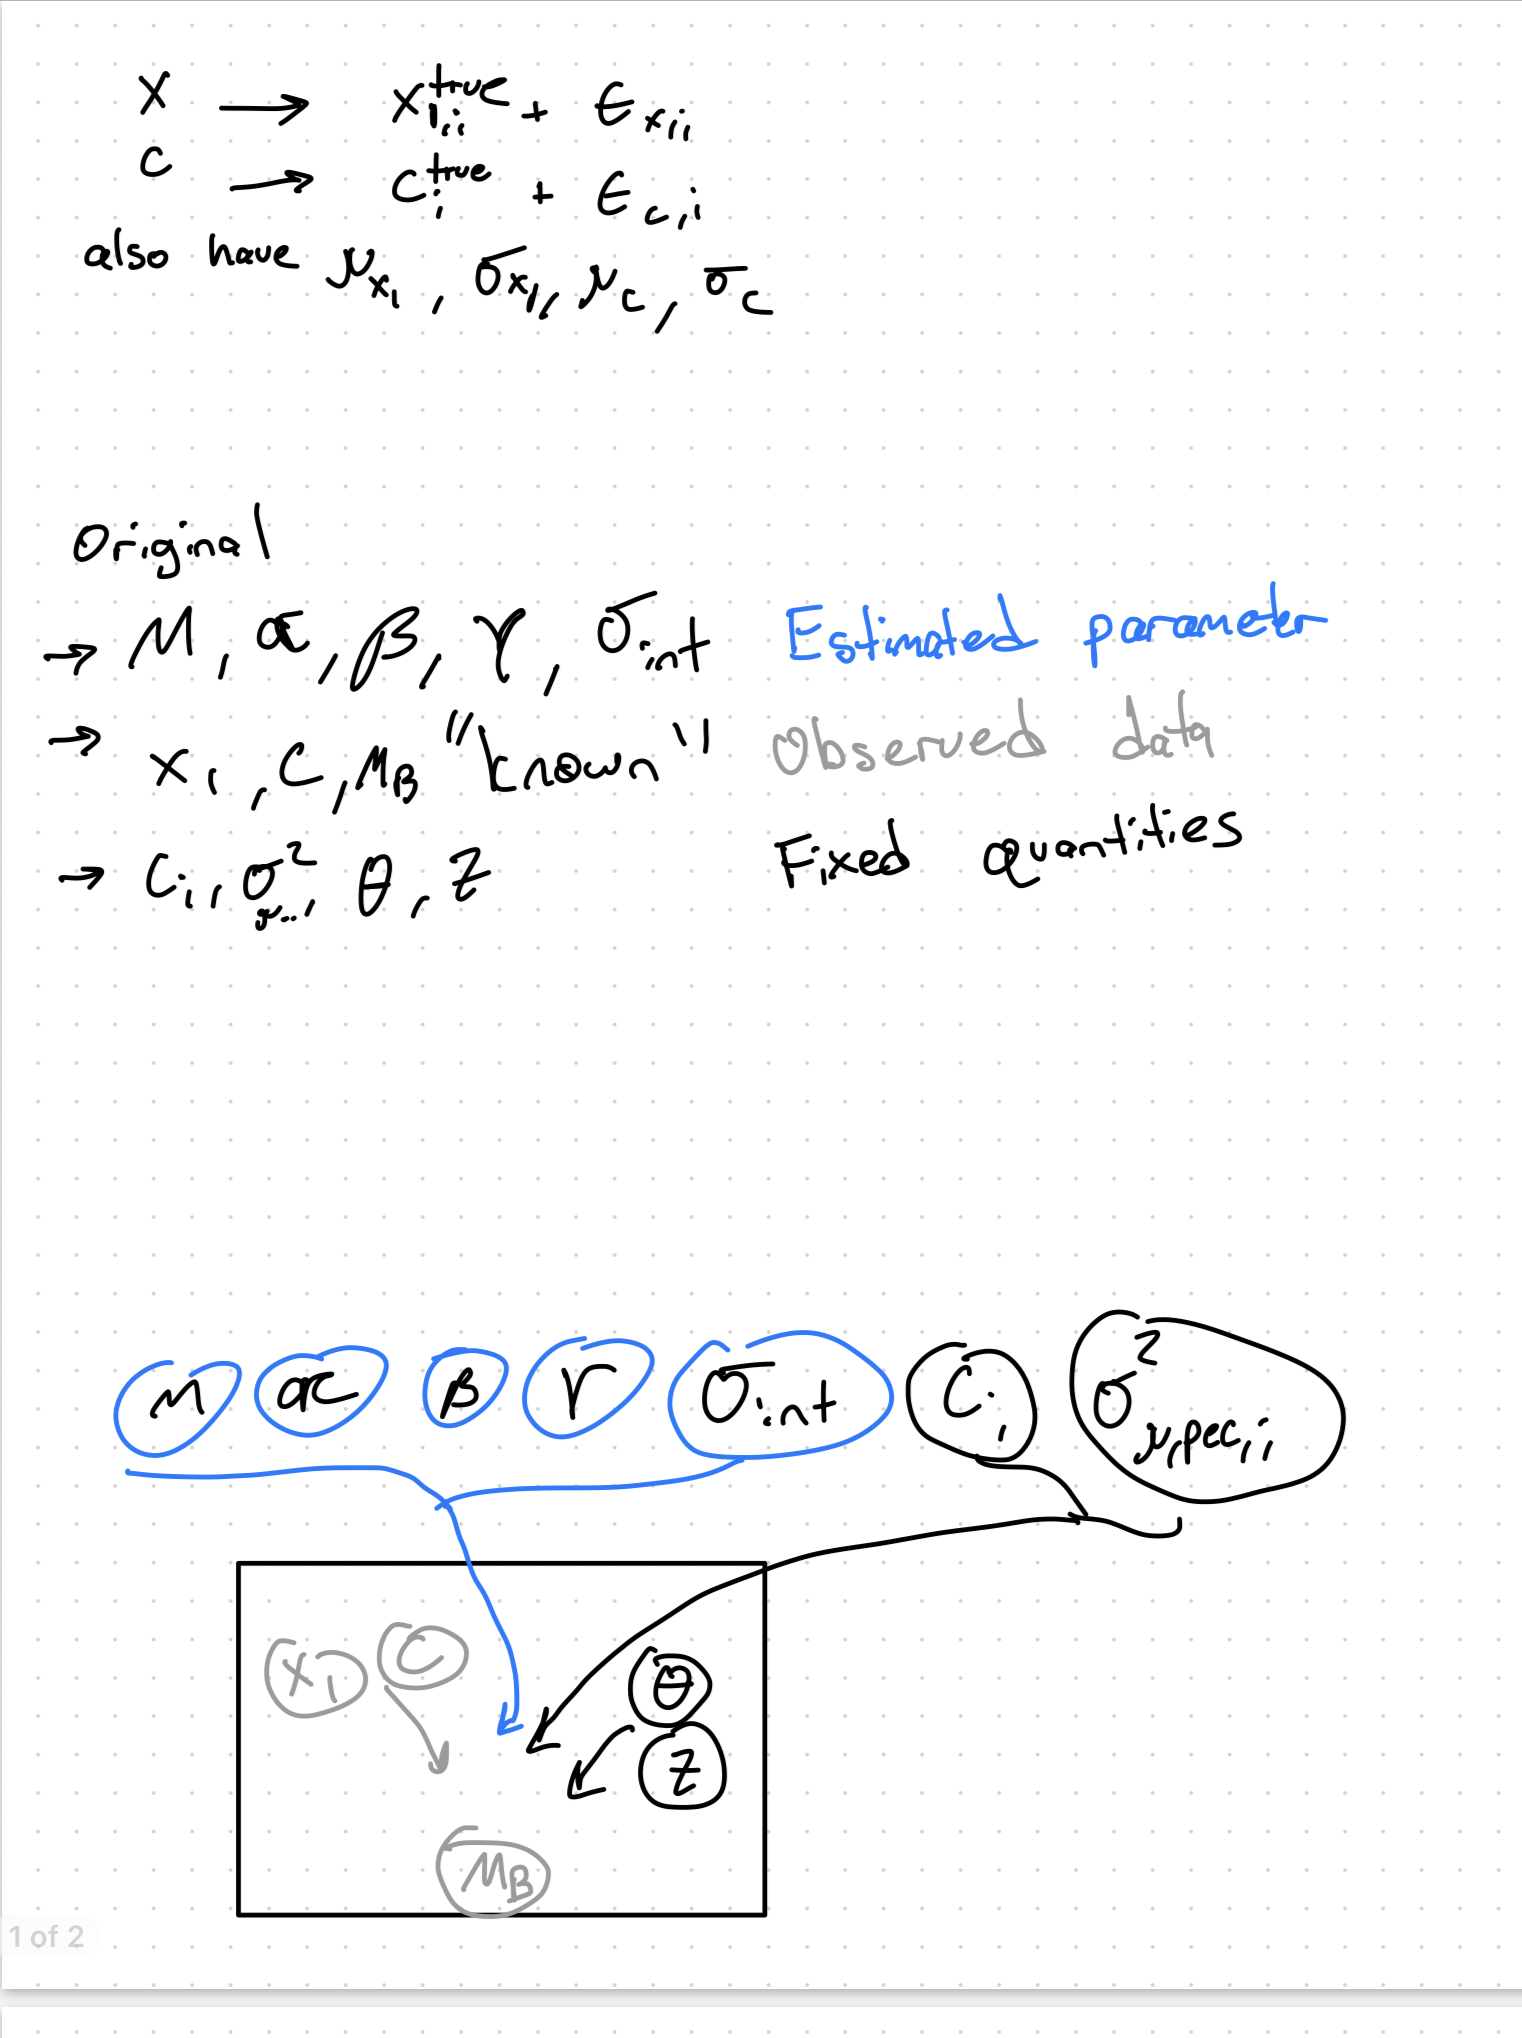

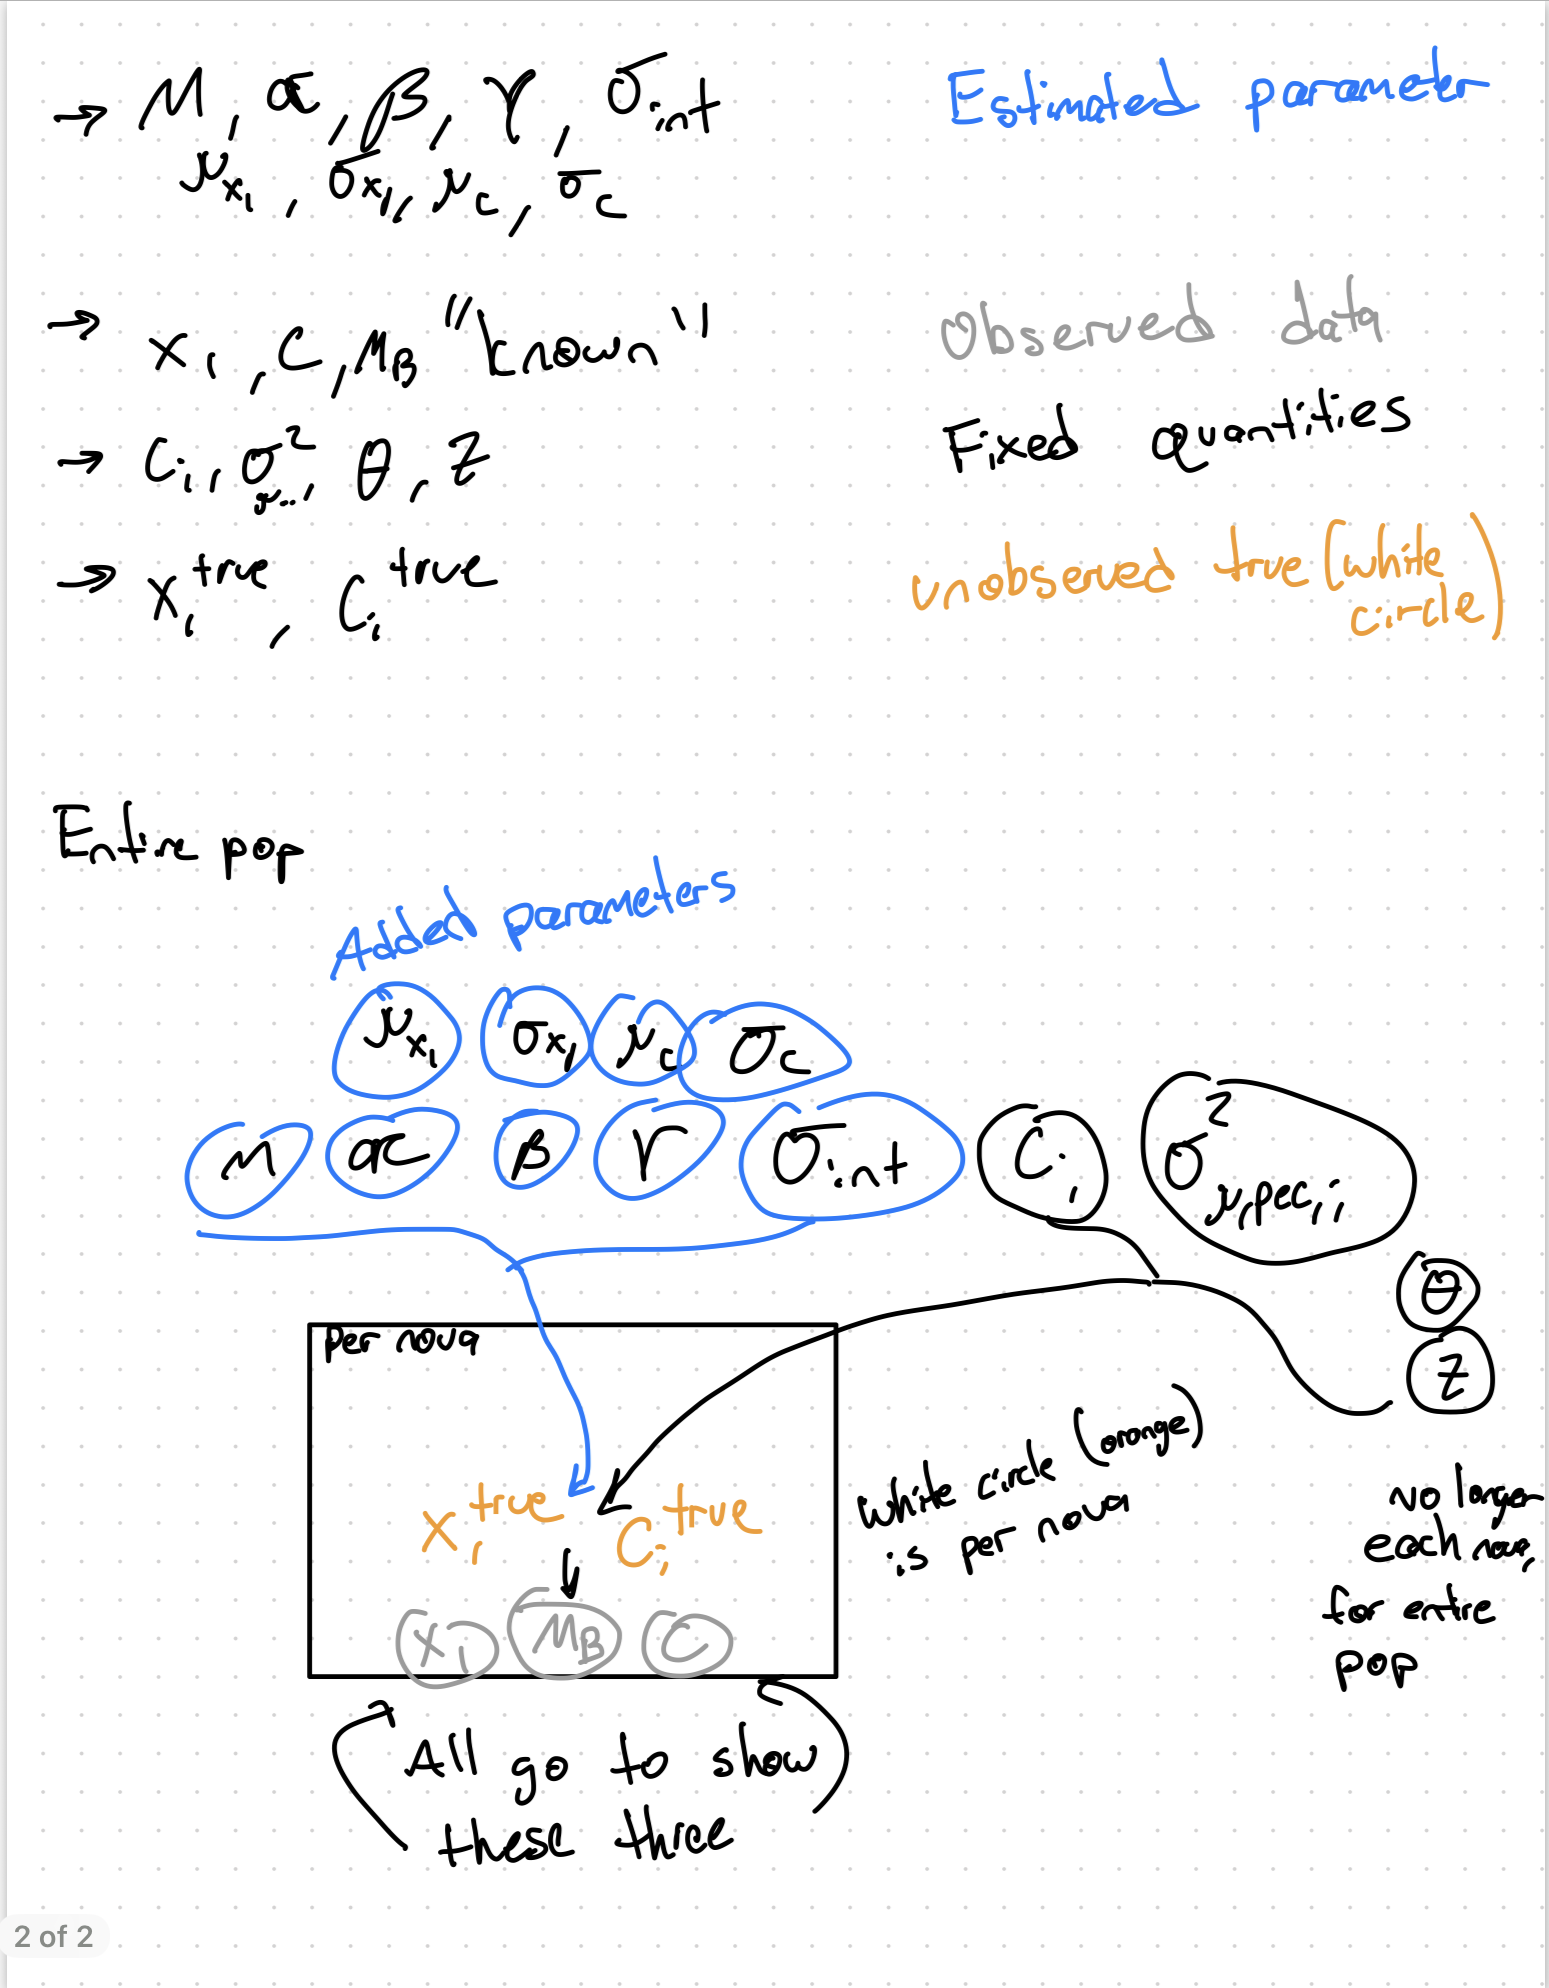

In [2]:
from astropy.cosmology import FlatLambdaCDM

# Load data
df = pd.read_csv(MIDTERM + 'p2_pantheon_sne.csv')

# Calculate distance modulus
cosmo = FlatLambdaCDM(H0=70, Om0=0.3)
df["mu"] = cosmo.distmod(df["z"]).value

# Identify the four contaminants using the same method as the midterm
df["residual"] = df["mB"] - df["mu"]
contaminant_idx = df.nlargest(4, "residual").index

# Remove those observations
df_fit = df.drop(index=contaminant_idx).copy()
d = df_fit.reset_index(drop=True)

print("Removed rows:", list(contaminant_idx))
print("Remaining supernovae:", len(d))

# Extract the observed measurements
mB = d["mB"].to_numpy()
x1 = d["x1"].to_numpy()
color = d["c"].to_numpy()

mu = d["mu"].to_numpy()
z = d["z"].to_numpy()
host = (d["host_logmass"].to_numpy() > 10).astype(int)

# Measurement uncertainties
sm = d["mB_err"].to_numpy()
sx = d["x1_err"].to_numpy()
sc = d["c_err"].to_numpy()

# Build the 3x3 measurement covariance matrix for every SN
N = len(d)
C = np.zeros((N, 3, 3))

C[:, 0, 0] = sm**2
C[:, 1, 1] = sx**2
C[:, 2, 2] = sc**2

C[:, 0, 1] = C[:, 1, 0] = d["cov_mB_x1"].to_numpy()
C[:, 0, 2] = C[:, 2, 0] = d["cov_mB_c"].to_numpy()
C[:, 1, 2] = C[:, 2, 1] = d["cov_x1_c"].to_numpy()

# Peculiar velocity uncertainty
c_light = 299792.458
sigma_pec = (5 / np.log(10)) * 250 / (c_light * z)

# Observed measurements as a single vector per supernova
observed = np.column_stack([mB, x1, color])

Removed rows: [91, 3, 197, 130]
Remaining supernovae: 246


In [3]:
print("STRETCH (x1)")
print("Observed standard deviation:", np.std(x1))
print("Mean measurement error:", np.mean(sx))

print("\nCOLOR (c)")
print("Observed standard deviation:", np.std(color))
print("Mean measurement error:", np.mean(sc))

STRETCH (x1)
Observed standard deviation: 1.0540268405707696
Mean measurement error: 0.20341518292682922

COLOR (c)
Observed standard deviation: 0.09098979642753785
Mean measurement error: 0.03487904471544715


In [4]:
with pm.Model() as hierarchical_model:

    # ---------------------------------
    # 1. Tripp relation parameters
    # ---------------------------------

    M = pm.Uniform("M", lower=-20, upper=-17)

    alpha = pm.Uniform("alpha", lower=0, upper=2)

    beta = pm.Uniform("beta", lower=0, upper=4)

    gamma = pm.Uniform("gamma", lower=-0.5, upper=0.5)

    sigma_int = pm.HalfNormal("sigma_int", sigma=0.3)


    # ---------------------------------
    # 2. Population distributions
    # ---------------------------------

    mu_x1 = pm.Normal("mu_x1", mu=0, sigma=2)

    sigma_x1 = pm.HalfNormal("sigma_x1", sigma=2)

    mu_c = pm.Normal("mu_c", mu=0, sigma=0.2)

    sigma_c = pm.HalfNormal("sigma_c", sigma=0.2)


    # ---------------------------------
    # 3. Latent true stretch and color
    # ---------------------------------

    x1_true = pm.Normal(
        "x1_true",
        mu=mu_x1,
        sigma=sigma_x1,
        shape=N
    )

    c_true = pm.Normal(
        "c_true",
        mu=mu_c,
        sigma=sigma_c,
        shape=N
    )


    # ---------------------------------
    # 4. Predicted apparent magnitude
    # ---------------------------------

    mB_true = (
        M
        + mu
        - alpha * x1_true
        + beta * c_true
        + gamma * host
    )


    # Expected values for all three measurements
    expected_values = pt.stack(
        [mB_true, x1_true, c_true],
        axis=1
    )


    # ---------------------------------
    # 5. Measurement covariance
    # ---------------------------------

    C_tensor = pt.as_tensor_variable(C)

    extra_cov = pt.zeros_like(C_tensor)

    # Add intrinsic scatter and peculiar velocity
    # to the magnitude variance only
    extra_cov = pt.set_subtensor(
        extra_cov[:, 0, 0],
        sigma_int**2 + sigma_pec**2
    )

    total_cov = C_tensor + extra_cov


    # ---------------------------------
    # 6. Joint likelihood
    # ---------------------------------

    measurements = pm.MvNormal(
        "measurements",
        mu=expected_values,
        cov=total_cov,
        observed=observed
    )


    # ---------------------------------
    # 7. Sample posterior
    # ---------------------------------

    idata = pm.sample(
        draws=2000,
        tune=2000,
        chains=4,
        cores=4,
        target_accept=0.95,
        random_seed=42,
        return_inferencedata=True
    )

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [M, alpha, beta, gamma, sigma_int, mu_x1, sigma_x1, mu_c, sigma_c, x1_true, c_true]


Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 38 seconds.


In [5]:
main_parameters = [
    "M",
    "alpha",
    "beta",
    "gamma",
    "sigma_int",
    "mu_x1",
    "sigma_x1",
    "mu_c",
    "sigma_c"
]

print(
    az.summary(
        idata,
        var_names=main_parameters,
        ci_prob=0.68
    )
)

               mean       sd eti68_lb eti68_ub  ess_bulk  ess_tail r_hat  \
M          -19.2728    0.014      -19      -19     10836      7054  1.00   
alpha        0.1471   0.0101     0.14     0.16     11232      7331  1.00   
beta           3.18    0.132        3      3.3      8675      6342  1.00   
gamma       -0.0561   0.0198   -0.076   -0.037     12023      7029  1.00   
sigma_int    0.1138   0.0088      0.1     0.12      8000      7161  1.00   
mu_x1       -0.0543   0.0669    -0.12    0.012     19365      6486  1.00   
sigma_x1     1.0337   0.0489     0.99      1.1     17592      6456  1.00   
mu_c       -0.00201  0.00565  -0.0076   0.0037     15789      7082  1.00   
sigma_c     0.08214  0.00447    0.078    0.086     11386      6874  1.00   

          mcse_mean  mcse_sd  
M           0.00013  9.4e-05  
alpha       9.5e-05  6.8e-05  
beta         0.0014    0.001  
gamma       0.00018  0.00013  
sigma_int   9.9e-05    7e-05  
mu_x1       0.00048  0.00034  
sigma_x1    0.00037  0

In [6]:
diagnostics = az.summary(
    idata,
    kind="diagnostics"
)

print("Maximum Rhat:", diagnostics["r_hat"].max())

print("Minimum bulk ESS:", diagnostics["ess_bulk"].min())

print(
    "Number of divergences:",
    int(idata.sample_stats["diverging"].sum())
)

Maximum Rhat: 1.00
Minimum bulk ESS: 8000
Number of divergences: 0


In [7]:

import numpy as np
from scipy.optimize import minimize

# ==================================================
# BEFORE RUNNING: PRE-REGISTER THE TEST
# ==================================================

theta_true = np.array([
    -19.27,       # M
    0.14,         # alpha
    2.90,         # beta
    -0.06,        # gamma
    np.log(0.12)  # ln(sigma_int)
])

bounds = [
    (-20, -17),
    (0, 2),
    (0, 4),
    (-0.5, 0.5),
    (np.log(0.1), np.log(0.2))
]

n_sim = 50
rng = np.random.default_rng(20261013)

print("PRE-REGISTERED FAILURE CRITERION")
print("Fail if gamma's 68% interval covers the truth in fewer than")
print("25 or more than 43 of the 50 simulations.")
print("True gamma:", theta_true[3])


# ==================================================
# PREPARE THE DATA
# ==================================================

# Covariance terms between measured quantities
cmx = d["cov_mB_x1"].to_numpy()
cmc = d["cov_mB_c"].to_numpy()
cxc = d["cov_x1_c"].to_numpy()


# ==================================================
# DEFINE THE MODEL
# ==================================================

def variance_for(theta):

    M, alpha, beta, gamma, ln_sigma_int = theta

    sigma_int = np.exp(ln_sigma_int)

    # Measurement variance, including covariance terms
    var_meas = (
        sm**2
        + alpha**2 * sx**2
        + beta**2 * sc**2
        + 2 * alpha * cmx
        - 2 * beta * cmc
        - 2 * alpha * beta * cxc
    )

    # Add peculiar velocity and intrinsic scatter
    return var_meas + sigma_pec**2 + sigma_int**2


def mean_magnitude(theta):

    M, alpha, beta, gamma, ln_sigma_int = theta

    return (
        M
        + mu
        - alpha * x1
        + beta * color
        + gamma * host
    )


# ==================================================
# GENERATE 50 SIMULATED DATASETS
# ==================================================

var_true = variance_for(theta_true)

if np.any(var_true <= 0):
    raise ValueError("Non-positive variance. Check covariance inputs.")

mean_true = mean_magnitude(theta_true)

simulated_magnitudes = np.array([
    mean_true + rng.normal(0, np.sqrt(var_true))
    for _ in range(n_sim)
])


# ==================================================
# DEFINE NEGATIVE LOG-LIKELIHOOD
# ==================================================

def make_nll(y):

    def nll(theta):

        var = variance_for(theta)

        if np.any(var <= 0) or not np.all(np.isfinite(var)):
            return 1e100

        residual = y - mean_magnitude(theta)

        return 0.5 * np.sum(
            np.log(2 * np.pi * var) + residual**2 / var
        )

    return nll


# ==================================================
# CALCULATE NUMERICAL HESSIAN
# ==================================================

def hessian_fd(f, x):

    x = np.asarray(x, dtype=float)
    n = len(x)

    H = np.zeros((n, n))

    h = 1e-4 * np.maximum(1.0, np.abs(x))
    f0 = f(x)

    for i in range(n):

        ei = np.zeros(n)
        ei[i] = h[i]

        H[i, i] = (
            f(x + ei) - 2 * f0 + f(x - ei)
        ) / h[i]**2

        for j in range(i + 1, n):

            ej = np.zeros(n)
            ej[j] = h[j]

            H[i, j] = (
                f(x + ei + ej)
                - f(x + ei - ej)
                - f(x - ei + ej)
                + f(x - ei - ej)
            ) / (4 * h[i] * h[j])

            H[j, i] = H[i, j]

    return H


# ==================================================
# FIT ALL SIMULATED DATASETS
# ==================================================

gamma_estimates = []
gamma_lower = []
gamma_upper = []

fit_success = 0
bad_curvature = 0

for j, y_sim in enumerate(simulated_magnitudes):

    nll = make_nll(y_sim)

    fit = minimize(
        nll,
        theta_true,
        method="L-BFGS-B",
        bounds=bounds
    )

    # Only continue if optimization succeeded
    if not fit.success or not np.all(np.isfinite(fit.x)):
        print(f"Fit {j + 1} failed:", fit.message)
        continue

    fit_success += 1

    # Calculate curvature around the maximum-likelihood solution
    H = hessian_fd(nll, fit.x)

    try:

        eigenvalues = np.linalg.eigvalsh(H)

        if np.any(eigenvalues <= 0):
            raise np.linalg.LinAlgError(
                "Hessian is not positive definite"
            )

        covariance = np.linalg.inv(H)

        if covariance[3, 3] <= 0:
            raise np.linalg.LinAlgError(
                "Invalid gamma variance"
            )

        gamma_hat = fit.x[3]
        gamma_se = np.sqrt(covariance[3, 3])

        gamma_estimates.append(gamma_hat)
        gamma_lower.append(gamma_hat - gamma_se)
        gamma_upper.append(gamma_hat + gamma_se)

    except np.linalg.LinAlgError:
        bad_curvature += 1


# ==================================================
# EVALUATE 68% INTERVAL COVERAGE
# ==================================================

gamma_estimates = np.array(gamma_estimates)
gamma_lower = np.array(gamma_lower)
gamma_upper = np.array(gamma_upper)

covered = (
    (gamma_lower <= theta_true[3])
    & (gamma_upper >= theta_true[3])
)

n_valid = len(covered)
n_covered = int(covered.sum())

coverage = n_covered / n_valid if n_valid > 0 else np.nan


# ==================================================
# PRINT RESULTS
# ==================================================

print("\nSIMULATION RESULTS")
print("------------------------------")

print("Successful optimizer fits:", fit_success, "/", n_sim)
print("Invalid curvature estimates:", bad_curvature)
print("Valid confidence intervals:", n_valid)

print("\nGamma results")
print("------------------------------")
print("True gamma:", theta_true[3])

if n_valid > 0:

    print("Mean fitted gamma:", round(np.mean(gamma_estimates), 4))
    print("SD of fitted gamma:", round(np.std(gamma_estimates, ddof=1), 4))

    print("Intervals containing true gamma:", n_covered, "/", n_valid)
    print("Coverage fraction:", round(coverage, 3))

    # Apply the pre-registered failure criterion
    if n_valid == n_sim and 25 <= n_covered <= 43:
        print("\nTEST PASSED")
    else:
        print("\nTEST FAILED or INCONCLUSIVE")

else:
    print("No valid intervals were produced.")
    print("\nTEST FAILED")


PRE-REGISTERED FAILURE CRITERION
Fail if gamma's 68% interval covers the truth in fewer than
25 or more than 43 of the 50 simulations.
True gamma: -0.06

SIMULATION RESULTS
------------------------------
Successful optimizer fits: 50 / 50
Invalid curvature estimates: 0
Valid confidence intervals: 50

Gamma results
------------------------------
True gamma: -0.06
Mean fitted gamma: -0.0544
SD of fitted gamma: 0.025
Intervals containing true gamma: 30 / 50
Coverage fraction: 0.6

TEST PASSED


**ANSWER (the two graphs, the table, the simulation result, then the explanation):**

If measurement errors are small compared to pop spread, centered parameterization works well. Large errors compared to pop spread would be non-centered. In my case, the pop spread is a good amount larger than the errors, so I would pick the centered model. It might be a good idea to watch color as its error is a little larger. 

I fit 50 simulated supernova datasets using redshifts, stretch, colors, host classifications, and covariance amtricies. I picked know parameters and a host-mass gamma of -0.06, and generated Tripp relation magnitudes usuing uncertainty, velocity uncertinaty, and intrinsic scatter.

To hit that 68% interval, fewer than 25 or more than 43 of the 50 calculated intervals containing true gamma would result in a failure.

It recovered a mean gamma of -0.0544 out of the -0.06 and 30 of the intervals contained true gamma. 30 falls within the pass condition I set above, though still on the lower side.

## Part 2: What the survey didn't keep (30%)

We'll use a simplified model of photon-counting aperture photometry. A source with true flux $F$ (in units of a reference flux $F_0$) gives, on average, $\epsilon F + \nu$ counts - $\epsilon = 226.27$ counts per $F_0$ is the exposure, and $\nu = 9.373$ counts is the background (sky plus detector) that lands in the aperture with or without a source. The survey keeps a source only if it counts $n > 32$ photons (about a 4$\sigma$ detection) - anything fainter never makes it into the catalog.

The true fluxes come from a **lognormal** population, $\ln F \sim \mathcal{N}(\mu, \sigma)$. Your catalog, `08/data/<your netid>.csv`, has one column, `n_counts`, for the first 1500 sources the survey detected. I generated it, so I know your $\mu$ and $\sigma$, and how many sources the survey missed. Your $\mu$ and $\sigma$ are graded by how far they are from the truth in units of your own error bars.

1. Histogram your counts (a log axis in $n$ helps). The paragraph above is how the survey was designed to work - your file is what it actually did. If you find something the paragraph doesn't describe, you'll have to deal with it, and there is more than one legitimate way to account for it. Reread Day 19's slides on what a survey doesn't keep before you decide. Make a call, and defend it. Explain what you found and how many sources it affects, what you did about it and why you chose that over the alternatives, and what it does to $\mu$ and $\sigma$ (show it - fit with and without your fix). Carry your choice through every fit below.
2. Write the sampling distribution of $n$ given $F$. Write the detection probability $p_{\rm det}(F) = P(n > 32 \mid F)$ in closed form using `scipy.special.gammainc` (the regularized lower incomplete gamma function - **be careful** whether the threshold is 32 or 33), and check it against `scipy.stats.poisson.sf` at a few fluxes. Plot $p_{\rm det}$ against $F$ on a log axis. At what flux is a source detected half the time?
3. Draw the graph for this survey, with the detection step in it (the selection graph from class is the model). Which nodes are latent, which are data, which are fixed, and where do $N$ and $N_{\rm det}$ go?
4. For a source that 2.1 doesn't affect, the naive likelihood of its count, with its true flux integrated out, is
$$p(n_i \mid \mu, \sigma) = \int \mathrm{Poisson}(n_i \mid \epsilon F + \nu)\, \mathcal{N}(\ln F \mid \mu, \sigma)\, d\ln F.$$
Do that integral on a grid in $\ln F$, and find the $(\mu, \sigma)$ that maximizes the product over your 1500 sources. Then add the detector by subtracting $N_{\rm det} \ln f_{\rm det}(\mu, \sigma)$ from the log-likelihood, with $f_{\rm det} = \int p_{\rm det}(F)\, \mathcal{N}(\ln F \mid \mu, \sigma)\, d\ln F$ the fraction of the population that the survey detects, and fit again. Report $(\mu, \sigma)$ for both fits with uncertainties (curvature, a grid of the posterior, or `PyMC` with `pm.Potential` - your choice, but state which). What is $f_{\rm det}$, and so about how many sources did your survey miss?
5. Histogram $\ln \hat F$, with $\hat F = (n - \nu)/\epsilon$. On it, draw the naive population (scaled to your 1500 sources) and the corrected population (scaled to the $N_{\rm det}/f_{\rm det}$ sources it says were there). Then simulate your survey from the corrected fit - sample that many true fluxes, sample a Poisson count for each, put the counts through your detector as it actually ran (2.1), keep the ones with $n > 32$, and plot the histogram of their $\ln \hat F$ on the same axes. Does it match your data? Now also draw the corrected population times $p_{\rm det}(F)$, and compare it with your histogram at the faint end. The fit is right, so why don't they match? (We gave this a name in class.) Finally, which way did ignoring the detector bias $\mu$ and $\sigma$? Explain why it biases both of them.

#### Hints:
- Use a grid in $\ln F$ from about $-14$ to $8$, with spacing no coarser than 0.01, and check that your answer doesn't change when you halve it.
- Unlike the LIGO example in class, there is no $\ln p_{\rm det}$ term for each source. Detection depends on $n$, which you observed, and every source in your catalog has $n > 32$.

In [8]:
# Part 2: your work here
n = pd.read_csv(LAB + f'{NETID}.csv')['n_counts'].to_numpy()
nu, eps, n_th = 9.373, 226.27, 32

Number of sources: 1500
Minimum counts: 33
Maximum counts: 1900
Mean counts: 278.47933333333333
Median counts: 93.0
Sources at or below detection threshold: 0
Non-integer count values: 0


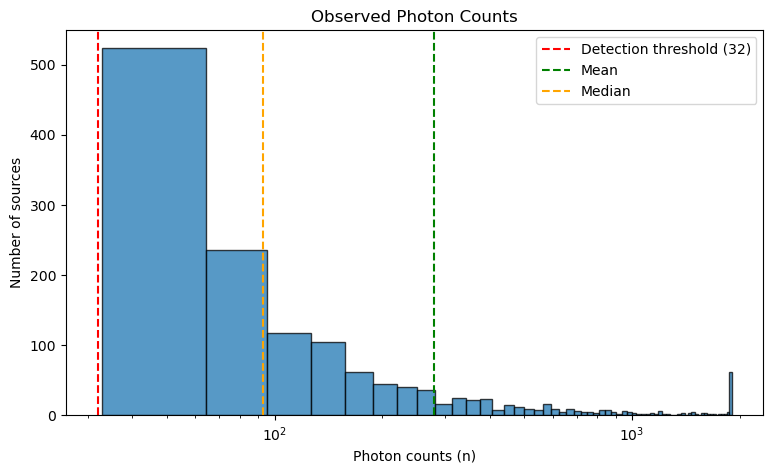


20 faintest sources:
[33 33 33 33 33 33 33 33 33 33 33 33 33 33 33 33 33 33 33 33]


In [9]:

import numpy as np
import matplotlib.pyplot as plt

# Basic inspection
print("Number of sources:", len(n))
print("Minimum counts:", n.min())
print("Maximum counts:", n.max())
print("Mean counts:", n.mean())
print("Median counts:", np.median(n))
print("Sources at or below detection threshold:", np.sum(n <= n_th))
print("Non-integer count values:", np.sum(n != np.floor(n)))

# Histogram of observed photon counts
plt.figure(figsize=(9, 5))

plt.hist(n, bins=60, edgecolor="black", alpha=0.75)

plt.axvline(
    n_th,
    color="red",
    linestyle="--",
    label="Detection threshold (32)"
)
plt.axvline(n.mean(), color="green",linestyle="--",label="Mean")
plt.axvline(np.median(n), color="orange",linestyle="--",label="Median")


plt.xscale("log")
plt.xlabel("Photon counts (n)")
plt.ylabel("Number of sources")
plt.title("Observed Photon Counts")
plt.legend()
plt.show()

# Look at the faintest observations
print("\n20 faintest sources:")
print(np.sort(n)[:20])


In [10]:
# Investigate the unusually large number of sources at 1900 counts

print("Number of sources recorded at exactly 1900:",
      np.sum(n == 1900))

print("\nCounts near the upper limit:")
print(np.sort(n)[-30:])

print("\nUnique values among the largest counts:")
print(np.unique(n[n >= 1800], return_counts=True))


Number of sources recorded at exactly 1900: 61

Counts near the upper limit:
[1900 1900 1900 1900 1900 1900 1900 1900 1900 1900 1900 1900 1900 1900
 1900 1900 1900 1900 1900 1900 1900 1900 1900 1900 1900 1900 1900 1900
 1900 1900]

Unique values among the largest counts:
(array([1829, 1840, 1860, 1864, 1900]), array([ 1,  2,  1,  1, 61]))


The minimum observation I get is lucky 33, above that 32 cutoff. However, there is something very suspicious that appears around 1900 on the photon count axis. It is possible there is an upper limit to the detector, so there is a n amount of photons that were detected from 33 to 1900, and some amount that were detected at at least 1900 or higher. 

In [11]:

# Count observations at exactly 1900
n_at_limit = np.sum(n == 1900)

print("Total sources:", len(n))
print("Sources recorded at 1900:", n_at_limit)
print("Percentage of catalog:", round(100 * n_at_limit / len(n), 2), "%")

# Count observations in the upper tail
for lower in [1500, 1600, 1700, 1800, 1850, 1900]:
    count = np.sum(n >= lower)
    print(f"Sources with counts >= {lower}: {count}")


Total sources: 1500
Sources recorded at 1900: 61
Percentage of catalog: 4.07 %
Sources with counts >= 1500: 78
Sources with counts >= 1600: 75
Sources with counts >= 1700: 70
Sources with counts >= 1800: 66
Sources with counts >= 1850: 63
Sources with counts >= 1900: 61


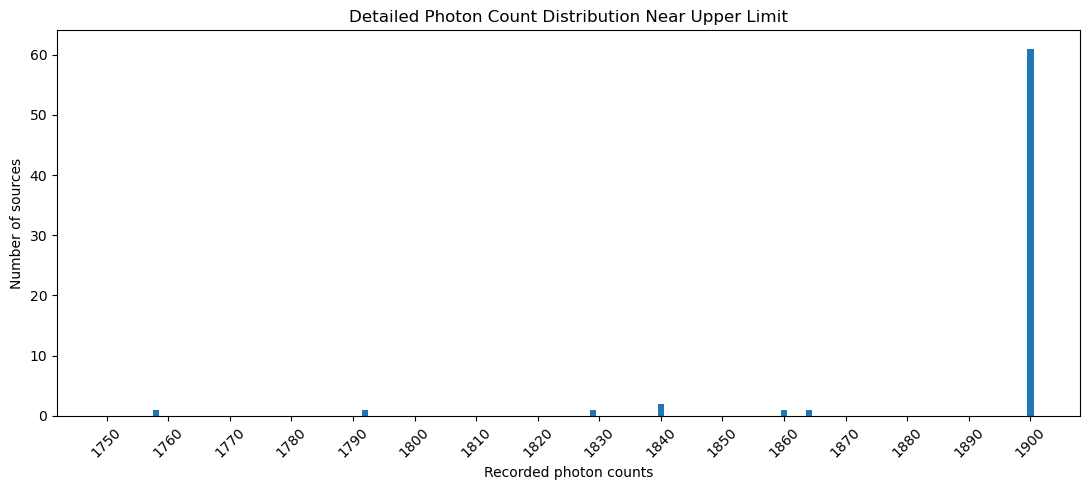

In [12]:

# Count frequency of each observed integer near the upper limit
upper_counts = np.arange(1750, 1901)

frequencies = np.array([
    np.sum(n == count)
    for count in upper_counts
])

plt.figure(figsize=(11, 5))

plt.bar(upper_counts, frequencies, width=1)

plt.xlabel("Recorded photon counts")
plt.ylabel("Number of sources")
plt.title("Detailed Photon Count Distribution Near Upper Limit")

plt.xticks(np.arange(1750, 1901, 10), rotation=45)
plt.tight_layout()
plt.show()

After more analysis, it looks like the theory above is probable. All of the 61 (or ~4% of the set) data points appear at 1900. It is likely that we need two probabilities:

One that focuses on 33 through 1899 where P(n = k | F)
One that is at 1900 where P(N >= 1900 | F)

I want to fit two versions of the same selection-correlated population model where one set is uncorrected at 1900 and corrected where they are at least 1900.

There should be no removal of these sources as it is likely that they are real.

In [13]:

import numpy as np
import matplotlib.pyplot as plt

from scipy.special import gammainc, gammaln, logsumexp
from scipy.optimize import minimize

# ==================================================
# 1. CONSTANTS AND INTEGRATION GRID
# ==================================================

nu = 9.373
eps = 226.27
n_th = 32
upper_limit = 1900

N_det = len(n)

# Grid in log flux
dlogF = 0.01
logF_grid = np.arange(-14, 8 + dlogF/2, dlogF)

F_grid = np.exp(logF_grid)
lambda_grid = eps * F_grid + nu

# Trapezoidal integration weights
integration_weights = np.ones(len(logF_grid)) * dlogF
integration_weights[0] = dlogF / 2
integration_weights[-1] = dlogF / 2

log_weights = np.log(integration_weights)

# Group identical observed counts to make optimization faster
unique_counts, count_frequencies = np.unique(n, return_counts=True)

print("Number of detected sources:", N_det)
print("Sources at upper limit:", np.sum(n == upper_limit))
print("Integration grid points:", len(logF_grid))


# ==================================================
# 2. DETECTION PROBABILITY
# ==================================================

# P(n > 32 | F) = P(n >= 33 | F)
p_det_grid = gammainc(33, lambda_grid)


# ==================================================
# 3. LOG-LIKELIHOOD
# ==================================================

def calculate_log_likelihood(theta, correct_upper_limit, account_detection):

    mu_pop, log_sigma = theta
    sigma_pop = np.exp(log_sigma)

    # Lognormal population density in log(F)
    log_population = (
        -0.5 * ((logF_grid - mu_pop) / sigma_pop)**2
        - np.log(sigma_pop)
        - 0.5 * np.log(2 * np.pi)
    )

    # Integrate the probability of each recorded count over true flux
    log_probabilities = []

    for observed_count in unique_counts:

        if correct_upper_limit and observed_count == upper_limit:

            # Recorded 1900 means actual count was >= 1900
            with np.errstate(divide="ignore"):
                log_poisson_probability = np.log(
                    gammainc(1900, lambda_grid)
                )

        else:

            # Ordinary exact Poisson count
            log_poisson_probability = (
                observed_count * np.log(lambda_grid)
                - lambda_grid
                - gammaln(observed_count + 1)
            )

        log_integrand = (
            log_poisson_probability
            + log_population
            + log_weights
        )

        log_probability = logsumexp(log_integrand)

        log_probabilities.append(log_probability)

    log_probabilities = np.array(log_probabilities)

    # Sum over all observed sources, accounting for repeated counts
    total_log_likelihood = np.sum(
        count_frequencies * log_probabilities
    )

    # Optional correction for the detection threshold
    if account_detection:

        log_f_det = logsumexp(
            np.log(p_det_grid)
            + log_population
            + log_weights
        )

        total_log_likelihood -= N_det * log_f_det

    return total_log_likelihood


# ==================================================
# 4. NEGATIVE LOG-LIKELIHOOD FOR OPTIMIZATION
# ==================================================

def make_negative_log_likelihood(correct_upper_limit, account_detection):

    def negative_log_likelihood(theta):

        log_likelihood = calculate_log_likelihood(
            theta,
            correct_upper_limit,
            account_detection
        )

        if not np.isfinite(log_likelihood):
            return 1e100

        return -log_likelihood

    return negative_log_likelihood


# ==================================================
# 5. NUMERICAL HESSIAN FOR UNCERTAINTIES
# ==================================================

def calculate_hessian(function, parameters):

    parameters = np.asarray(parameters, dtype=float)

    number_parameters = len(parameters)
    H = np.zeros((number_parameters, number_parameters))

    steps = 1e-4 * np.maximum(1.0, np.abs(parameters))
    f0 = function(parameters)

    for i in range(number_parameters):

        ei = np.zeros(number_parameters)
        ei[i] = steps[i]

        H[i, i] = (
            function(parameters + ei)
            - 2 * f0
            + function(parameters - ei)
        ) / steps[i]**2

        for j in range(i + 1, number_parameters):

            ej = np.zeros(number_parameters)
            ej[j] = steps[j]

            H[i, j] = (
                function(parameters + ei + ej)
                - function(parameters + ei - ej)
                - function(parameters - ei + ej)
                + function(parameters - ei - ej)
            ) / (4 * steps[i] * steps[j])

            H[j, i] = H[i, j]

    return H


# ==================================================
# 6. FIT ALL FOUR MODELS
# ==================================================

# Initial guesses based on observed flux estimates
F_observed = (n - nu) / eps
logF_observed = np.log(F_observed)

mu_start = np.median(logF_observed)
sigma_start = max(np.std(logF_observed), 0.3)

initial_guess = np.array([
    mu_start,
    np.log(sigma_start)
])

bounds = [
    (-14, 8),       # mu
    (-5, 2)         # log(sigma)
]

models = [
    ("No upper-limit correction, no detection correction", False, False),
    ("Upper-limit correction only", True, False),
    ("Detection correction only", False, True),
    ("Both corrections", True, True)
]

results = {}

for name, correct_upper, account_detection in models:

    nll = make_negative_log_likelihood(
        correct_upper,
        account_detection
    )

    fit = minimize(
        nll,
        initial_guess,
        method="L-BFGS-B",
        bounds=bounds
    )

    if not fit.success:
        print("WARNING:", name, fit.message)

    # Calculate curvature-based uncertainties
    H = calculate_hessian(nll, fit.x)

    eigenvalues = np.linalg.eigvalsh(H)

    if np.any(eigenvalues <= 0):
        print("WARNING: Invalid Hessian for", name)
        mu_error = np.nan
        sigma_error = np.nan

    else:

        covariance = np.linalg.inv(H)

        mu_error = np.sqrt(covariance[0, 0])

        sigma_hat = np.exp(fit.x[1])

        # Convert log(sigma) uncertainty to sigma uncertainty
        sigma_error = sigma_hat * np.sqrt(covariance[1, 1])

    mu_hat = fit.x[0]
    sigma_hat = np.exp(fit.x[1])

    results[name] = {
        "mu": mu_hat,
        "sigma": sigma_hat,
        "mu_error": mu_error,
        "sigma_error": sigma_error,
        "fit": fit
    }


# ==================================================
# 7. DISPLAY RESULTS
# ==================================================

print("\nPOPULATION FIT RESULTS")
print("=" * 85)

for name, result in results.items():

    print("\n", name)
    print(f"mu    = {result['mu']:.4f} +/- {result['mu_error']:.4f}")
    print(f"sigma = {result['sigma']:.4f} +/- {result['sigma_error']:.4f}")


# ==================================================
# 8. DETECTED FRACTION AND MISSED SOURCES
# ==================================================

corrected_result = results["Both corrections"]

mu_corrected = corrected_result["mu"]
sigma_corrected = corrected_result["sigma"]

log_population = (
    -0.5 * ((logF_grid - mu_corrected) / sigma_corrected)**2
    - np.log(sigma_corrected)
    - 0.5 * np.log(2 * np.pi)
)

f_det = np.sum(
    p_det_grid * np.exp(log_population) * integration_weights
)

estimated_total = N_det / f_det
estimated_missed = estimated_total - N_det

print("\nDETECTION RESULTS")
print("=" * 40)
print(f"Detected fraction: {f_det:.4f}")
print(f"Estimated total population: {estimated_total:.0f}")
print(f"Estimated missed sources: {estimated_missed:.0f}")


Number of detected sources: 1500
Sources at upper limit: 61
Integration grid points: 2201

POPULATION FIT RESULTS

 No upper-limit correction, no detection correction
mu    = -0.6796 +/- 0.0313
sigma = 1.2047 +/- 0.0222

 Upper-limit correction only
mu    = -0.6624 +/- 0.0326
sigma = 1.2516 +/- 0.0239

 Detection correction only
mu    = -2.1675 +/- 0.2181
sigma = 1.9577 +/- 0.0967

 Both corrections
mu    = -3.0286 +/- 0.4212
sigma = 2.3674 +/- 0.1591

DETECTION RESULTS
Detected fraction: 0.3781
Estimated total population: 3967
Estimated missed sources: 2467


The biggest changes to mu and sigma come when you use detection correction only or both types of correction. This likely shows that the detection catalog is missing quire a large portion of faint samples. The hidden distribution is likely a lot wider than the fit says.

The upper-limit correetion has a lot smaller of an impact than the detection correction. We will repeat with a halved grid space.

In [14]:

# Save the original results for comparison
results_coarse = results.copy()

# Create the finer integration grid
dlogF_fine = 0.005

logF_grid = np.arange(-14, 8 + dlogF_fine/2, dlogF_fine)
F_grid = np.exp(logF_grid)
lambda_grid = eps * F_grid + nu

# Trapezoidal integration weights
integration_weights = np.ones(len(logF_grid)) * dlogF_fine
integration_weights[0] = dlogF_fine / 2
integration_weights[-1] = dlogF_fine / 2

log_weights = np.log(integration_weights)

# Recalculate detection probabilities on the finer grid
p_det_grid = gammainc(33, lambda_grid)

print("Fine grid points:", len(logF_grid))

# Repeat all four fits
results_fine = {}

for name, correct_upper, account_detection in models:

    nll = make_negative_log_likelihood(
        correct_upper,
        account_detection
    )

    fit = minimize(
        nll,
        initial_guess,
        method="L-BFGS-B",
        bounds=bounds
    )

    H = calculate_hessian(nll, fit.x)

    if not fit.success or np.any(np.linalg.eigvalsh(H) <= 0):
        print("Problem with fit:", name)
        continue

    covariance = np.linalg.inv(H)

    mu_hat = fit.x[0]
    sigma_hat = np.exp(fit.x[1])

    mu_error = np.sqrt(covariance[0, 0])
    sigma_error = sigma_hat * np.sqrt(covariance[1, 1])

    results_fine[name] = {
        "mu": mu_hat,
        "sigma": sigma_hat,
        "mu_error": mu_error,
        "sigma_error": sigma_error
    }

# Compare coarse and fine grids
print("\nGRID CONVERGENCE COMPARISON")
print("=" * 85)

for name in results_fine:

    coarse = results_coarse[name]
    fine = results_fine[name]

    print("\n", name)

    print(
        f"mu: {coarse['mu']:.6f} -> {fine['mu']:.6f} "
        f"(change = {fine['mu'] - coarse['mu']:+.6f})"
    )

    print(
        f"sigma: {coarse['sigma']:.6f} -> {fine['sigma']:.6f} "
        f"(change = {fine['sigma'] - coarse['sigma']:+.6f})"
    )


Fine grid points: 4401

GRID CONVERGENCE COMPARISON

 No upper-limit correction, no detection correction
mu: -0.679565 -> -0.679565 (change = -0.000000)
sigma: 1.204684 -> 1.204684 (change = -0.000000)

 Upper-limit correction only
mu: -0.662432 -> -0.662432 (change = -0.000000)
sigma: 1.251650 -> 1.251650 (change = +0.000000)

 Detection correction only
mu: -2.167528 -> -2.167530 (change = -0.000002)
sigma: 1.957744 -> 1.957744 (change = +0.000001)

 Both corrections
mu: -3.028645 -> -3.028668 (change = -0.000023)
sigma: 2.367389 -> 2.367393 (change = +0.000004)


As hoped, there is barely any change.

In [15]:

from scipy.stats import poisson
from scipy.optimize import brentq

# Test several flux values
test_fluxes = [0.01, 0.05, 0.10, 0.20, 0.50, 1.0, 2.0]

print("DETECTION PROBABILITY CHECK")
print("Flux       gammainc       poisson.sf       Difference")

for F in test_fluxes:

    lam = eps * F + nu

    probability_gamma = gammainc(33, lam)
    probability_poisson = poisson.sf(32, lam)

    difference = abs(probability_gamma - probability_poisson)

    print(
        f"{F:<10.3f}"
        f"{probability_gamma:<15.8f}"
        f"{probability_poisson:<16.8f}"
        f"{difference:.2e}"
    )


# Find the flux where detection probability equals 50%
def detection_difference(F):
    return gammainc(33, eps * F + nu) - 0.5

F_half = brentq(detection_difference, 0.00001, 1.0)

print("\nFlux where detection probability is 50%:")
print("F =", F_half)


DETECTION PROBABILITY CHECK
Flux       gammainc       poisson.sf       Difference
0.010     0.00000023     0.00000023      0.00e+00
0.050     0.00756595     0.00756595      0.00e+00
0.100     0.45317141     0.45317141      0.00e+00
0.200     0.99934979     0.99934979      0.00e+00
0.500     1.00000000     1.00000000      0.00e+00
1.000     1.00000000     1.00000000      0.00e+00
2.000     1.00000000     1.00000000      0.00e+00

Flux where detection probability is 50%:
F = 0.10294900731085664


Here, we checked the incomplete gamma with the SciPy Poission

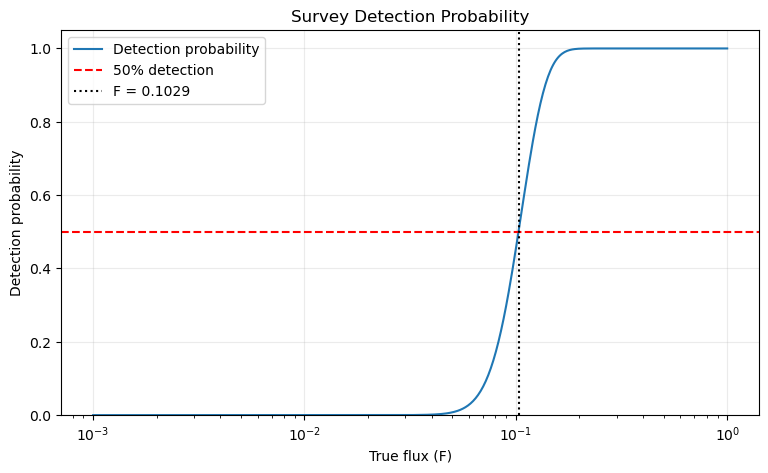

In [16]:

F_plot = np.logspace(-3, 0, 500)

p_plot = gammainc(33, eps * F_plot + nu)

plt.figure(figsize=(9, 5))

plt.plot(F_plot, p_plot, label="Detection probability")

plt.axhline(0.5, color="red", linestyle="--", label="50% detection")
plt.axvline(F_half, color="black", linestyle=":", label=f"F = {F_half:.4f}")

plt.xscale("log")
plt.xlabel("True flux (F)")
plt.ylabel("Detection probability")
plt.title("Survey Detection Probability")
plt.ylim(0, 1.05)
plt.legend()
plt.grid(alpha=0.25)
plt.show()


In [17]:

# Get corrected fine-grid parameters
mu_corrected = results_fine["Both corrections"]["mu"]
sigma_corrected = results_fine["Both corrections"]["sigma"]

log_population = (
    -0.5 * ((logF_grid - mu_corrected) / sigma_corrected)**2
    - np.log(sigma_corrected)
    - 0.5 * np.log(2 * np.pi)
)

population_density = np.exp(log_population)

f_det = np.sum(
    p_det_grid * population_density * integration_weights
)

estimated_total = N_det / f_det
estimated_missed = estimated_total - N_det

print("FINE GRID POPULATION ESTIMATES")
print("mu:", mu_corrected)
print("sigma:", sigma_corrected)
print("Detected fraction:", f_det)
print("Estimated total sources:", round(estimated_total))
print("Estimated missed sources:", round(estimated_missed))


FINE GRID POPULATION ESTIMATES
mu: -3.0286676911045753
sigma: 2.367393116902636
Detected fraction: 0.37813870471677674
Estimated total sources: 3967
Estimated missed sources: 2467


Estimated detection fraction: 0.37813870471677674
Estimated underlying population: 3967
Expected missed sources: 2467

SIMULATED SURVEY
Sources generated: 3967
Sources detected: 1490
Sources missed: 2477
Sources recorded at upper limit: 70


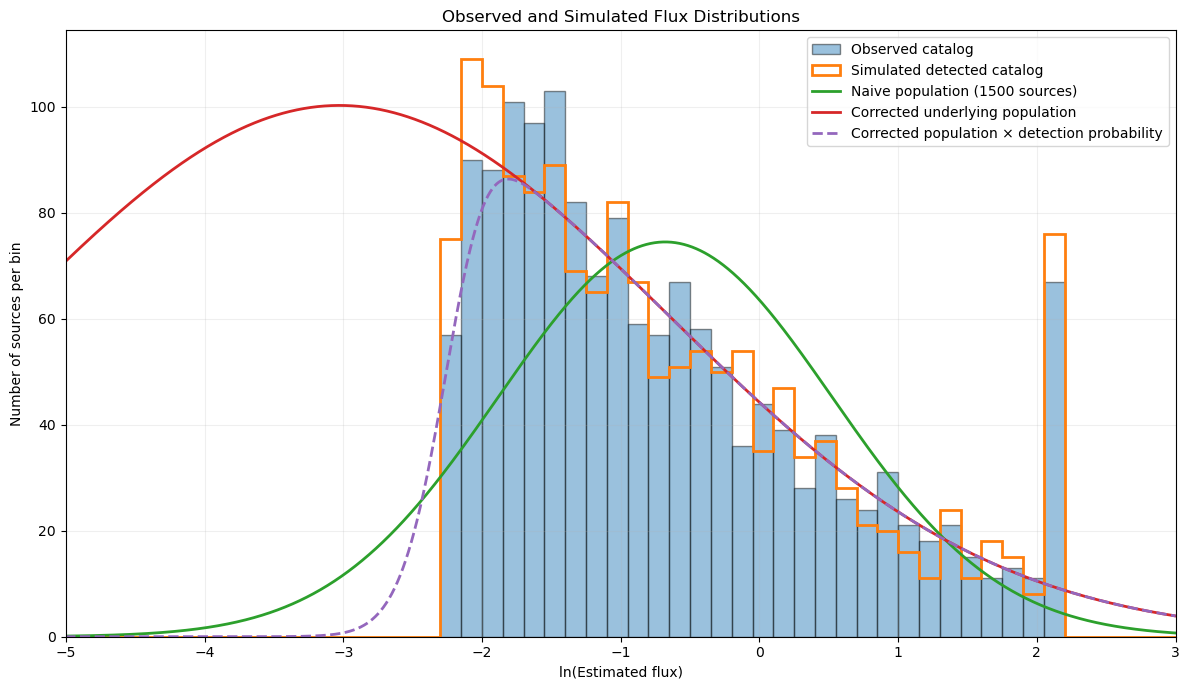

In [18]:

# ==================================================
# PART 2.5: SIMULATE THE CORRECTED SURVEY
# ==================================================

# Use the fine-grid fit results
mu_naive = results_fine[
    "No upper-limit correction, no detection correction"
]["mu"]

sigma_naive = results_fine[
    "No upper-limit correction, no detection correction"
]["sigma"]

mu_corrected = results_fine["Both corrections"]["mu"]
sigma_corrected = results_fine["Both corrections"]["sigma"]

# Recalculate detection fraction using corrected parameters
log_population = (
    -0.5 * ((logF_grid - mu_corrected) / sigma_corrected)**2
    - np.log(sigma_corrected)
    - 0.5 * np.log(2 * np.pi)
)

population_density = np.exp(log_population)

f_det = np.sum(
    p_det_grid * population_density * integration_weights
)

# Estimated total number of sources
N_total = int(round(N_det / f_det))

print("Estimated detection fraction:", f_det)
print("Estimated underlying population:", N_total)
print("Expected missed sources:", N_total - N_det)


# ==================================================
# DRAW A SIMULATED POPULATION
# ==================================================

rng = np.random.default_rng(20261103)

# Draw true fluxes from the corrected lognormal population
simulated_true_fluxes = rng.lognormal(
    mean=mu_corrected,
    sigma=sigma_corrected,
    size=N_total
)

# Generate actual Poisson photon counts
simulated_true_counts = rng.poisson(
    eps * simulated_true_fluxes + nu
)

# Apply the apparent upper recording limit
simulated_recorded_counts = np.minimum(
    simulated_true_counts,
    upper_limit
)

# Apply the actual detection threshold
detected_mask = simulated_true_counts > n_th

simulated_detected_counts = simulated_recorded_counts[detected_mask]

# Convert recorded counts into estimated fluxes
simulated_detected_fluxes = (
    simulated_detected_counts - nu
) / eps

simulated_log_flux_estimates = np.log(simulated_detected_fluxes)

print("\nSIMULATED SURVEY")
print("Sources generated:", N_total)
print("Sources detected:", len(simulated_detected_counts))
print("Sources missed:", N_total - len(simulated_detected_counts))
print("Sources recorded at upper limit:",
      np.sum(simulated_detected_counts == upper_limit))


# ==================================================
# OBSERVED FLUX ESTIMATES
# ==================================================

observed_flux_estimates = (n - nu) / eps
observed_log_flux_estimates = np.log(observed_flux_estimates)


# ==================================================
# CALCULATE POPULATION CURVES
# ==================================================

# Naive population, scaled to 1500 observed sources
naive_density = (
    np.exp(
        -0.5 * ((logF_grid - mu_naive) / sigma_naive)**2
    )
    / (sigma_naive * np.sqrt(2 * np.pi))
)

naive_curve = N_det * naive_density

# Corrected underlying population, scaled to estimated total N
corrected_curve = N_total * population_density

# Corrected population after applying detection probability
detected_population_curve = (
    N_total * population_density * p_det_grid
)


# ==================================================
# PLOT HISTOGRAM AND POPULATION DISTRIBUTIONS
# ==================================================

bin_width = 0.15

bins = np.arange(
    min(observed_log_flux_estimates.min(), logF_grid.min()),
    max(observed_log_flux_estimates.max(), logF_grid.max()) + bin_width,
    bin_width
)

plt.figure(figsize=(12, 7))

# Observed catalog
plt.hist(
    observed_log_flux_estimates,
    bins=bins,
    alpha=0.45,
    label="Observed catalog",
    edgecolor="black"
)

# Simulated detected catalog
plt.hist(
    simulated_log_flux_estimates,
    bins=bins,
    histtype="step",
    linewidth=2,
    label="Simulated detected catalog"
)

# Population curves: convert density per unit ln(F) to expected counts per bin
plt.plot(
    logF_grid,
    naive_curve * bin_width,
    label="Naive population (1500 sources)",
    linewidth=2
)

plt.plot(
    logF_grid,
    corrected_curve * bin_width,
    label="Corrected underlying population",
    linewidth=2
)

plt.plot(
    logF_grid,
    detected_population_curve * bin_width,
    label="Corrected population × detection probability",
    linewidth=2,
    linestyle="--"
)

plt.xlabel("ln(Estimated flux)")
plt.ylabel("Number of sources per bin")
plt.title("Observed and Simulated Flux Distributions")
plt.xlim(-5, 3)
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


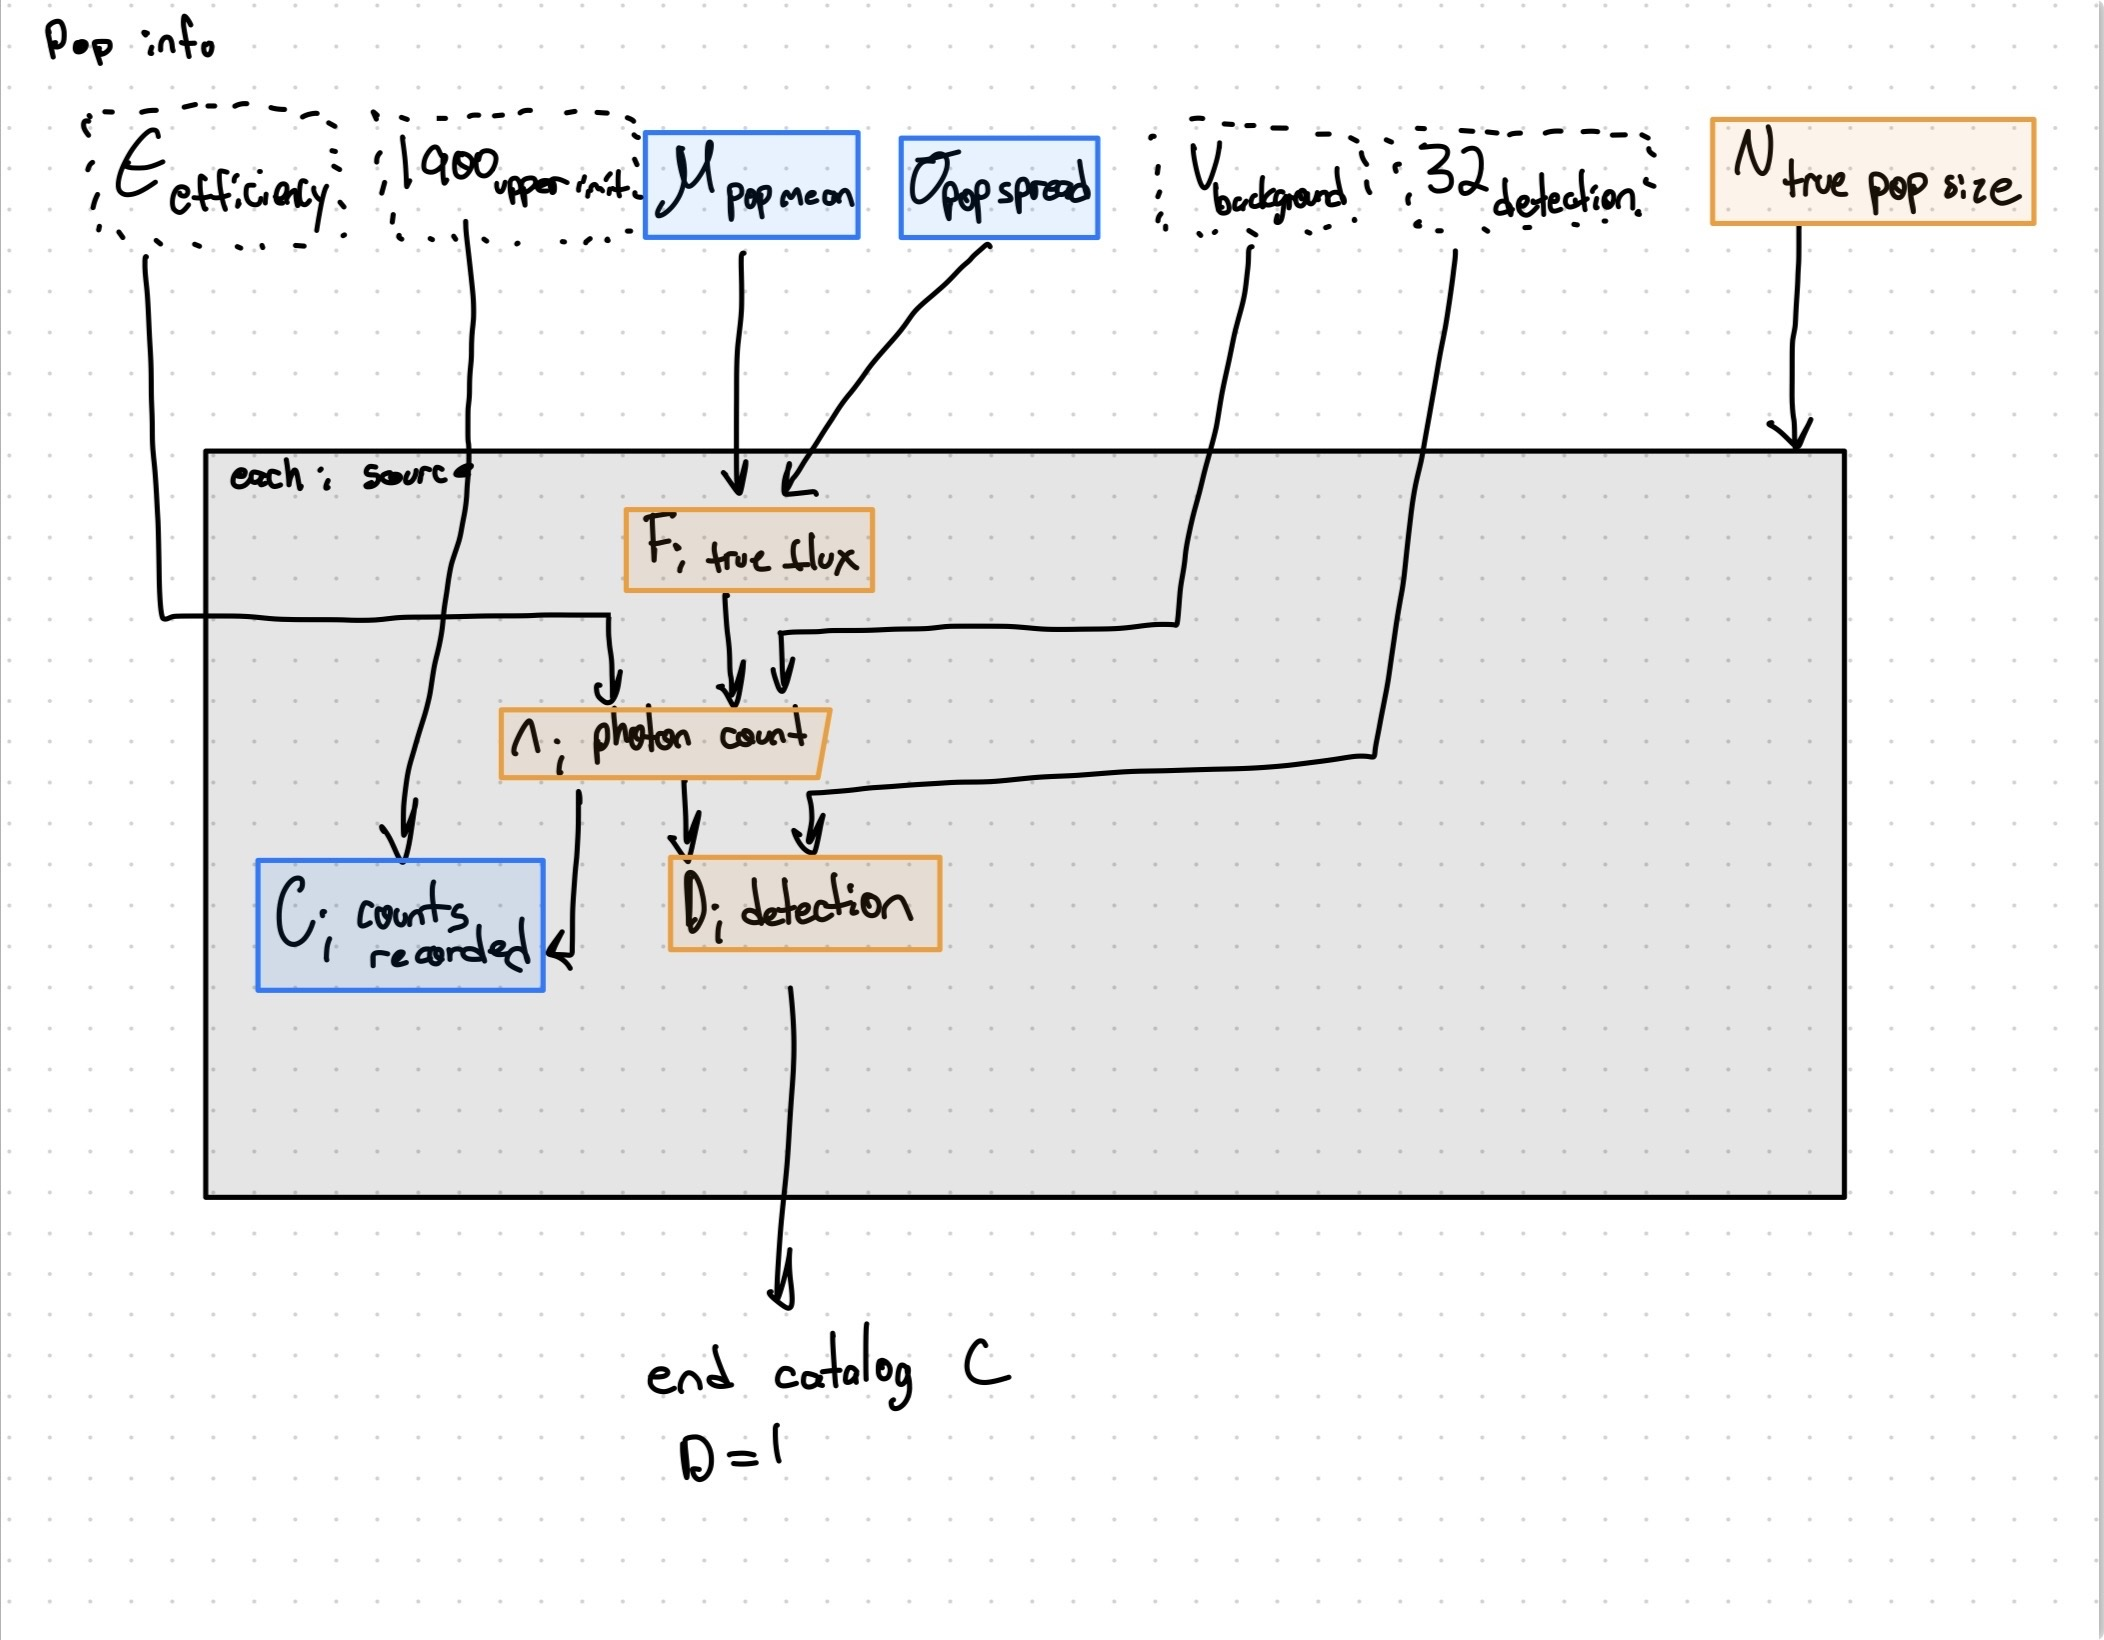

**ANSWER (the two fits, f_det and the number missed, then the explanation):**

Initially, I made two estimates from the source population. One accounted for the upper limit around 1900 and one for the begining to the limit. 

When I tested for fits without detection normalization (upper limit but not correcting), the values were:
mu=-0.6624+-0.0326, sigma=1.2517+-0.0239

When testing detection normalization, the values became
mu=-3.0287+-0.4212, sigma=2.3674+-0.1591

The estimated detection fraction for this corrected population was 0.3781. This means that ~37% of the scores were expected to be detected by the survey. Since we detected 1500 scores, the total population is 3967, meaning it missed 2467.

With such a large difference in the mu and sigma between the two fits, there was a high potential that the survey was missing a large portion of detections. Without detection normalization, the fit the fit describes the catalog as if it were representative of the entire population, however, the faint sources are not as likely to get above the 32 count detection, meaning they are underrepresented. Including the detection normalizatoin accounts for the missing sources, making the inferred population shift toward lower fluxes and gets a smaller mu and larger sigma. I estimate that there were around 2500 missed sources.

## Part 3: A supernova in two dimensions (25%)

This one is real. The Carnegie Supernova Project (CSP-I) observed nearby Type Ia supernovae in six optical bands, from $u$ (364 nm) to $i$ (761 nm). Look up your supernova and your held-out band in `08/data/csp_assignments.csv`. Your light curve is `08/data/csp/<SN>.csv`, with columns `mjd`, `band`, `wavelength_A` (the band's effective wavelength), `flux_ujy` and `flux_err_ujy` (flux density in μJy), and the magnitudes they came from. The header gives the redshift and the date of maximum light in $B$. Data: Krisciunas et al. 2017, AJ 154, 211 (CC BY 4.0; credit the Carnegie Supernova Project).

Work in rest-frame phase, $(\mathrm{MJD} - T_{B\,\rm max})/(1+z)$, from $-10$ to $+40$ days, and divide every flux by the peak $B$ flux. Note that `V0`, `V1` and `V` are three versions of the same filter (within 32 Å) - treat them as one band, $V$.

A supernova's light curves in neighboring bands look alike, so a Gaussian process in **two** inputs, phase and wavelength, can learn all six at once and predict a band it never saw.

1. Plot every band against phase.
2. Fit a GP to the flux as a function of (phase, wavelength) using every band **except** your held-out one, with wavelength in microns (so both inputs are numbers of order 1-50). Use a kernel with its own length scale in phase and in wavelength (an anisotropic squared-exponential) times a fitted amplitude, each point's own measurement error, and a small white-noise term that you also fit. Fit the hyperparameters by maximizing the marginal likelihood (as in Lab 07), from more than one start. `sklearn`'s `GaussianProcessRegressor` (with `alpha` set to the squared errors, `normalize_y=False`, and `ConstantKernel` times `RBF` plus `WhiteKernel`) or your own Cholesky code from Lab 07 are both fine. Report the two length scales, and comment on what each means physically for a supernova.
3. Predict your held-out band at its epochs, with the GP's $1\sigma$ band, and plot it over the data. Report the rms residual as a fraction of the peak, and the fraction of held-out points within $1\sigma$ (add the GP's variance and the measurement variance). Does the GP's error bar look reasonable?
4. Now hold out $u$ instead, and report the same two numbers. Why is this so much harder? Think particularly about what the kernel assumes, and how far $u$ is from the other bands compared with your first held-out band.

In [19]:
# Part 3: your work here
asg = pd.read_csv(LAB + 'csp_assignments.csv')
SN, HOLD = asg.loc[asg.netid == NETID, ['sn', 'holdout_band']].iloc[0]
path = LAB + f'csp/{SN}.csv'
hdr = [l for l in open(path) if l.startswith('#')]          # the header lines: source, license, redshift, date of B maximum
z = float([l for l in hdr if 'z_helio' in l][0].split(':')[-1])
tmax = float([l for l in hdr if 'B-max MJD' in l][0].split(':')[1].split('+/-')[0])
d = pd.read_csv(path, comment='#')
d['band'] = d['band'].replace({'V0': 'V', 'V1': 'V'})   # V0, V1 and V are the same filter - treat them as one band
print(f'{SN}: z = {z}, B maximum at MJD {tmax}, {len(d)} points; held-out band: {HOLD}')

SN2007af: z = 0.0055, B maximum at MJD 54174.07, 157 points; held-out band: g


In [20]:
# Calculate rest-frame phase
d['phase'] = (d['mjd'] - tmax) / (1 + z)

# Convert wavelength from Angstroms to microns
d['wavelength_um'] = d['wavelength_A'] / 10000

# Keep only observations between -10 and +40 days
d = d[(d['phase'] >= -10) & (d['phase'] <= 40)].copy()

# Find the peak B-band flux
B_data = d[d['band'] == 'B']
peak_B_flux = B_data['flux_ujy'].max()

print("Peak B flux:", peak_B_flux, "microJy")

# Normalize flux and uncertainty
d['flux_norm'] = d['flux_ujy'] / peak_B_flux
d['flux_err_norm'] = d['flux_err_ujy'] / peak_B_flux

# Inspect the resulting data
print(d[['phase', 'band', 'wavelength_um',
         'flux_norm', 'flux_err_norm']].head())

print("\nBands:", sorted(d['band'].unique()))
print("Number of observations:", len(d))

Peak B flux: 19370.0 microJy
      phase band  wavelength_um  flux_norm  flux_err_norm
0 -8.722029    u        0.36393   0.266753       0.003686
1 -8.722029    B        0.43506   0.475632       0.004817
2 -8.722029    V        0.53752   0.443056       0.003263
3 -8.722029    i        0.76092   0.379556       0.002447
4 -7.727499    u        0.36393   0.331802       0.005214

Bands: ['B', 'V', 'g', 'i', 'r', 'u']
Number of observations: 117


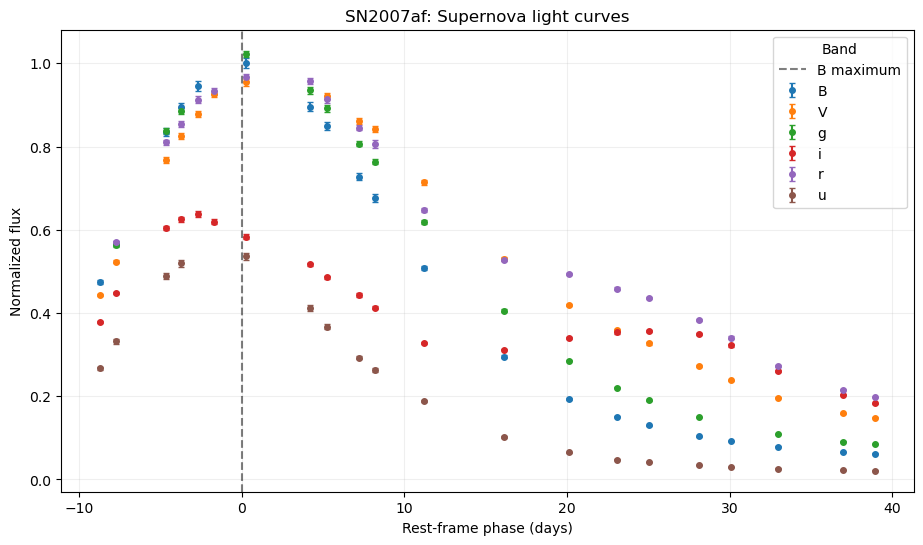

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 6))

for band in sorted(d['band'].unique()):

    band_data = d[d['band'] == band]

    plt.errorbar(
        band_data['phase'],
        band_data['flux_norm'],
        yerr=band_data['flux_err_norm'],
        fmt='o',
        markersize=4,
        capsize=2,
        label=band
    )

plt.axvline(0, color='black', linestyle='--',
            alpha=0.5, label='B maximum')

plt.xlabel('Rest-frame phase (days)')
plt.ylabel('Normalized flux')
plt.title(f'{SN}: Supernova light curves')
plt.legend(title='Band')
plt.grid(alpha=0.2)
plt.show()

In [22]:
# Separate training and held-out observations
train = d[d['band'] != HOLD].copy()
test = d[d['band'] == HOLD].copy()

print("Training observations:", len(train))
print("Testing observations:", len(test))

# Two input variables: phase and wavelength
X_train = train[['phase', 'wavelength_um']].to_numpy()
X_test = test[['phase', 'wavelength_um']].to_numpy()

# Target: normalized flux
y_train = train['flux_norm'].to_numpy()
y_test = test['flux_norm'].to_numpy()

# Individual measurement variances
measurement_variance = train['flux_err_norm'].to_numpy()**2

# Measurement errors for the held-out observations
test_variance = test['flux_err_norm'].to_numpy()**2

print("Training input shape:", X_train.shape)
print("Testing input shape:", X_test.shape)
print("Held-out wavelength:", test['wavelength_um'].unique())

Training observations: 100
Testing observations: 17
Training input shape: (100, 2)
Testing input shape: (17, 2)
Held-out wavelength: [0.47651]


In [23]:
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import (
    RBF,
    ConstantKernel,
    WhiteKernel
)

# Overall signal amplitude
amplitude = ConstantKernel(
    constant_value=1.0,
    constant_value_bounds=(0.01, 100)
)

# Separate length scales for phase and wavelength
rbf = RBF(
    length_scale=[10.0, 0.1],
    length_scale_bounds=[
        (1.0, 100.0),
        (0.01, 1.0)
    ]
)

# Additional fitted white-noise term
white_noise = WhiteKernel(
    noise_level=0.001,
    noise_level_bounds=(1e-8, 0.1)
)

# Combine the kernel components
kernel = amplitude * rbf + white_noise

print(kernel)



1**2 * RBF(length_scale=[10, 0.1]) + WhiteKernel(noise_level=0.001)


In [24]:
gp = GaussianProcessRegressor(
    kernel=kernel,
    alpha=measurement_variance,
    normalize_y=False,
    n_restarts_optimizer=10,
    random_state=42
)

gp.fit(X_train, y_train)

print("Optimized kernel:")
print(gp.kernel_)

print("\nLog marginal likelihood:")
print(gp.log_marginal_likelihood_value_)

Optimized kernel:
0.292**2 * RBF(length_scale=[7.52, 0.125]) + WhiteKernel(noise_level=1e-08)

Log marginal likelihood:
241.58352877916633


/Applications/anaconda3/envs/astr457/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-08. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


In [25]:
# Extract the optimized kernel
fitted_kernel = gp.kernel_

# The kernel structure is:
# ConstantKernel * RBF + WhiteKernel

amplitude_squared = fitted_kernel.k1.k1.constant_value

phase_length = fitted_kernel.k1.k2.length_scale[0]
wavelength_length = fitted_kernel.k1.k2.length_scale[1]

white_noise_level = fitted_kernel.k2.noise_level

print("FITTED GP HYPERPARAMETERS")
print("-------------------------")
print("Amplitude squared:", amplitude_squared)
print("Phase length scale:", phase_length, "days")
print("Wavelength length scale:", wavelength_length, "microns")
print("White noise level:", white_noise_level)# Predict held-out fluxes
y_pred, y_pred_std = gp.predict(
    X_test,
    return_std=True
)

# Add GP predictive variance and measurement variance
total_std = np.sqrt(
    y_pred_std**2 + test_variance
)

# Calculate residuals
residuals = y_test - y_pred

# Root mean square residual
rms = np.sqrt(np.mean(residuals**2))

# Fraction of points within 1 sigma
within_one_sigma = np.abs(residuals) <= total_std

fraction_within = np.mean(within_one_sigma)

print("HELD-OUT BAND RESULTS:", HOLD)
print("--------------------------------")
print("RMS residual:", rms)
print("RMS as percentage of peak:", rms * 100, "%")
print("Fraction within 1 sigma:", fraction_within)
print("Percentage within 1 sigma:", fraction_within * 100, "%")

FITTED GP HYPERPARAMETERS
-------------------------
Amplitude squared: 0.08538491611247385
Phase length scale: 7.518064782858227 days
Wavelength length scale: 0.12450503506507012 microns
White noise level: 9.999999999999982e-09
HELD-OUT BAND RESULTS: g
--------------------------------
RMS residual: 0.02321956770611071
RMS as percentage of peak: 2.321956770611071 %
Fraction within 1 sigma: 0.17647058823529413
Percentage within 1 sigma: 17.647058823529413 %


In [26]:
# Predict held-out fluxes
y_pred, y_pred_std = gp.predict(
    X_test,
    return_std=True
)

# Add GP predictive variance and measurement variance
total_std = np.sqrt(
    y_pred_std**2 + test_variance
)

# Calculate residuals
residuals = y_test - y_pred

# Root mean square residual
rms = np.sqrt(np.mean(residuals**2))

# Fraction of points within 1 sigma
within_one_sigma = np.abs(residuals) <= total_std

fraction_within = np.mean(within_one_sigma)

print("HELD-OUT BAND RESULTS:", HOLD)
print("--------------------------------")
print("RMS residual:", rms)
print("RMS as percentage of peak:", rms * 100, "%")
print("Fraction within 1 sigma:", fraction_within)
print("Percentage within 1 sigma:", fraction_within * 100, "%")

HELD-OUT BAND RESULTS: g
--------------------------------
RMS residual: 0.02321956770611071
RMS as percentage of peak: 2.321956770611071 %
Fraction within 1 sigma: 0.17647058823529413
Percentage within 1 sigma: 17.647058823529413 %


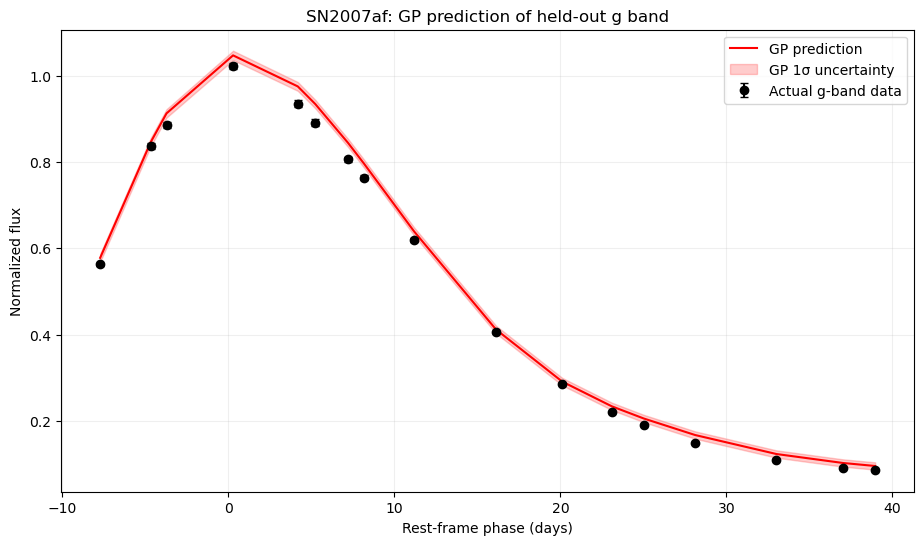

In [27]:
# Sort by phase for a clean prediction line
order = np.argsort(test['phase'].to_numpy())

phase_test = test['phase'].to_numpy()[order]
observed_flux = y_test[order]
predicted_flux = y_pred[order]
predicted_std = y_pred_std[order]
observed_error = test['flux_err_norm'].to_numpy()[order]

plt.figure(figsize=(11, 6))

# Actual held-out observations
plt.errorbar(
    phase_test,
    observed_flux,
    yerr=observed_error,
    fmt='o',
    color='black',
    capsize=3,
    label='Actual g-band data'
)

# GP prediction
plt.plot(
    phase_test,
    predicted_flux,
    color='red',
    label='GP prediction'
)

# GP uncertainty band
plt.fill_between(
    phase_test,
    predicted_flux - predicted_std,
    predicted_flux + predicted_std,
    color='red',
    alpha=0.2,
    label='GP 1σ uncertainty'
)

plt.xlabel('Rest-frame phase (days)')
plt.ylabel('Normalized flux')
plt.title(f'{SN}: GP prediction of held-out {HOLD} band')
plt.legend()
plt.grid(alpha=0.2)
plt.show()

In [28]:
# Separate training and testing data
train_u = d[d['band'] != 'u'].copy()
test_u = d[d['band'] == 'u'].copy()

# Prepare two-dimensional inputs
X_train_u = train_u[['phase', 'wavelength_um']].to_numpy()
X_test_u = test_u[['phase', 'wavelength_um']].to_numpy()

# Normalized flux
y_train_u = train_u['flux_norm'].to_numpy()
y_test_u = test_u['flux_norm'].to_numpy()

# Individual measurement variances
alpha_u = train_u['flux_err_norm'].to_numpy()**2
test_variance_u = test_u['flux_err_norm'].to_numpy()**2

# Create a fresh kernel with the same initial settings
amplitude_u = ConstantKernel(
    1.0,
    constant_value_bounds=(0.01, 100)
)

rbf_u = RBF(
    length_scale=[10.0, 0.1],
    length_scale_bounds=[
        (1.0, 100.0),
        (0.01, 1.0)
    ]
)

white_u = WhiteKernel(
    noise_level=0.001,
    noise_level_bounds=(1e-8, 0.1)
)

kernel_u = amplitude_u * rbf_u + white_u

# Fit the new GP
gp_u = GaussianProcessRegressor(
    kernel=kernel_u,
    alpha=alpha_u,
    normalize_y=False,
    n_restarts_optimizer=10,
    random_state=42
)

gp_u.fit(X_train_u, y_train_u)

print("Optimized u-band kernel:")
print(gp_u.kernel_)

Optimized u-band kernel:
0.287**2 * RBF(length_scale=[7.39, 0.142]) + WhiteKernel(noise_level=1e-08)


/Applications/anaconda3/envs/astr457/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-08. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


In [29]:
# Predict u-band fluxes
y_pred_u, y_pred_std_u = gp_u.predict(
    X_test_u,
    return_std=True
)

# Combine GP and measurement variance
total_std_u = np.sqrt(
    y_pred_std_u**2 + test_variance_u
)

# Calculate residuals
residuals_u = y_test_u - y_pred_u

# RMS residual
rms_u = np.sqrt(np.mean(residuals_u**2))

# Fraction within one sigma
within_one_sigma_u = np.abs(residuals_u) <= total_std_u

fraction_within_u = np.mean(within_one_sigma_u)

print("\nHELD-OUT U-BAND RESULTS")
print("-----------------------")
print("RMS residual:", rms_u)
print("RMS as percentage of peak:", rms_u * 100, "%")
print("Fraction within 1 sigma:", fraction_within_u)
print("Percentage within 1 sigma:", fraction_within_u * 100, "%")


HELD-OUT U-BAND RESULTS
-----------------------
RMS residual: 0.15788978523025882
RMS as percentage of peak: 15.788978523025882 %
Fraction within 1 sigma: 0.05263157894736842
Percentage within 1 sigma: 5.263157894736842 %


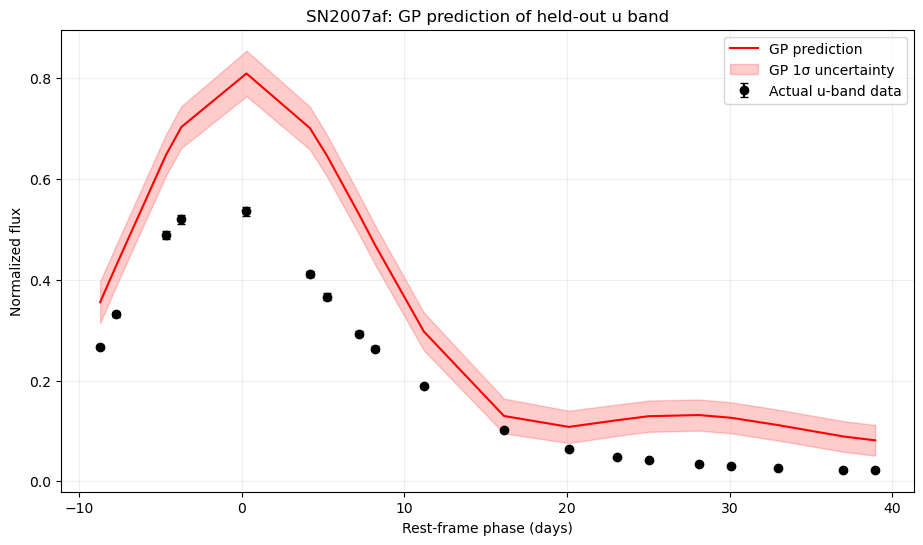

In [30]:
# Sort observations by phase
order_u = np.argsort(test_u['phase'].to_numpy())

phase_u = test_u['phase'].to_numpy()[order_u]
observed_u = y_test_u[order_u]
predicted_u = y_pred_u[order_u]
predicted_std_u = y_pred_std_u[order_u]
measurement_error_u = test_u['flux_err_norm'].to_numpy()[order_u]
combined_std_u = total_std_u[order_u]

plt.figure(figsize=(11, 6))

plt.errorbar(
    phase_u,
    observed_u,
    yerr=measurement_error_u,
    fmt='o',
    color='black',
    capsize=3,
    label='Actual u-band data'
)

plt.plot(
    phase_u,
    predicted_u,
    color='red',
    label='GP prediction'
)

plt.fill_between(
    phase_u,
    predicted_u - predicted_std_u,
    predicted_u + predicted_std_u,
    color='red',
    alpha=0.2,
    label='GP 1σ uncertainty'
)

plt.xlabel('Rest-frame phase (days)')
plt.ylabel('Normalized flux')
plt.title(f'{SN}: GP prediction of held-out u band')
plt.legend()
plt.grid(alpha=0.2)
plt.show()

In [31]:
# Create a summary table comparing g and u

summary = pd.DataFrame({
    'Held-out Band': ['g', 'u'],
    'Phase Length Scale (days)': [
        gp.kernel_.k1.k2.length_scale[0],
        gp_u.kernel_.k1.k2.length_scale[0]
    ],
    'Wavelength Length Scale (microns)': [
        gp.kernel_.k1.k2.length_scale[1],
        gp_u.kernel_.k1.k2.length_scale[1]
    ],
    'RMS Residual': [
        rms,
        rms_u
    ],
    'RMS (% of Peak)': [
        rms * 100,
        rms_u * 100
    ],
    'Within 1 Sigma (%)': [
        fraction_within * 100,
        fraction_within_u * 100
    ]
})

# Display the table
display(summary.round(4))

,Held-out Band,Phase Length Scale (days),Wavelength Length Scale (microns),RMS Residual,RMS (% of Peak),Within 1 Sigma (%)
0,g,7.5181,0.1245,0.0232,2.322,17.6471
1,u,7.3875,0.1415,0.1579,15.789,5.2632


**ANSWER (length scales, the two held-out tests, then why u is harder):**

When holding out the g-band, the Gaussian optimizer found a phase length of 7.518 days and wavelength scale of 0.1245 microns. The phase length scale describes how quickly the SN's brightness changes over time. A vlaye of 7.518 days shows that observations need to occur relatively quickly to be correlated. This shows the supernova brightness as it increases and fades.

The wavelength scale describes how quickly the correlations decrease at different wavelengths. Since the value is around 0.12, that indicates that observations in near filters are more stronyl correlated than observations in filters at further apart wavelengths.

When holdig out the u-band, the phase was 7.3875 and the wavelength scale was 0.1415, within very similar values and meaning as the g-band.

The u-band is the most difficult to predict because it is the shortest wavelength. The g-band is predictable because it can use wavelengths higher and lower than it, while the U-band sits at the bottom. The squared-exponential kernel works well for this situation as it assumes less correlation as the separation between wavelength increases. 

## Part 4: AI-use appendix and verification plan (10%)

1. **AI use**: which tools, for what, what they got wrong, and how you caught it. "I didn't use any" is fine if true.
2. **Reflection**: what would have gone wrong in your answer if you had not checked the AI's output? Name the specific thing.
3. **Verification plan**: the checks you ran before trusting your Part 1 and Part 2 numbers, and what failure would have looked like for each. Part 1.3 is already one. For Part 2, one check to consider is to simulate a catalog yourself with a $\mu$ and $\sigma$ you choose, through the same detector, run both fits on it, and see whether the corrected fit gets back what you put in and the naive one doesn't. One catalog isn't enough - comment on how many you'd need.

**AI-USE APPENDIX:**

I used ChatGPT as an assistant throughout the lab. I spend quite a lot of time undestanding the information presented, while also developing code, debugging errors, and interpreting results. I used it in part 1 to understand the graphs and model plot creation. Part two, I used it to develop likeihood and simulation code, as well as understanding the Poission probablility and detection threshold values. For part three, I used it to create the Gaussian Processes and the anisotropic kernel and its lengths. Also, the band hold outs.

I did not typically just accept the solutions without understanding the general idea. If I had a question or wondered why something was done that way, it became a discussion and I asked and clarified. The best example of this was the spike at 1900 counts. Should they be thrown away, modeled differently, what should happen? I went back and forth as well as consulted my lecture documentation to figure this out, rather than just following ChatGPT. 
**REFLECTION:**

The most clear impact could have been in part two when taking a look at the 1900 detection. Someone could have mistaken the detector to have collected examples at 1900 and not that there was some probability that they were at least 1900 and should be modeled differently. This would impact the brightest scores and could bias the estimated underlying flux. 

Another big issue was the threshold for survery detection being so high at 32. The entire source population likely includes lower fluxes than that, but they were scraped due to being lower than 32. There would be a bias in the underling population if this is true. 

Finally, the last issue has to deal with the G and U-band RMS residuals. While both models gave nice values and reproductions of U-band, the RMS residual went from 2.3 in G-band to 15.7 in U-band, making the model look like it performs better when it might not. 
**VERIFICATION PLAN:**

For 1, I simulated data knowing an underlying relationship. I used repeated simulations rather than using one single dataset. The checks were to see if the model could recover the known relationships. Failure would have been the inability to collect that data (within some threshold) again.

For part 2, I calculated probability of detection in two methods, gamma and poission. Those results agreed with the flux. Failure would be shows a disagreement between the methods, indicating a possibly incorrect gamme function. I also Repeated likelihood fits on the 0.01 grid spacing as well as 0.005. THe grid was fine as the fitted results were not bouncing around. I additionally investigated the 1900 source limit to see if different probability estimation modesl would need to be used. 